# 1-board: compensation

Find what the board's own chain adds to a current reading at low current, and how best to take each term out, so a speed estimated from the back-EMF at low speed does not carry the board. The largest term is the current zero. The shunt amplifier sits at one zero with the bridge asleep and at another with it awake, the step between them grows with the rail, and a method that tracks the zero on the board, a dynamic two-zero tracker, is specified here and graded against the stage 1 captures and two motors' stage 2 captures. The firmware takes its zero method and its constants from this result.

## Purpose

A servo estimates its speed from the back-EMF, the terminal volts less the copper's drop $R\,i$, over $K_e$. At low speed the EMF is a few tens of millivolts and the current a few tens of milliamps, so an error in the current's zero goes straight into the speed: one count of zero error is $R \cdot 0.88\,\mathrm{mA} / K_e$, about 0.53 rev/s on an MG90 motor, and the budget a speed estimate works to at low speed is 0.5 rev/s, under a count. The board's zero is not one number. Stage 1 found the current channel's rest zero at 1206 counts and an in-drive offset of about 5 counts over it, fitted as one constant from 3.7 to 8 V. The stage 2 captures hold the two zeros side by side on every cycle, the torque-off rest before each chain and the open bridge after each coast cut, at three rails, so the step and its shape against the rail can be read there with hundreds of spins behind each number.

The question has two parts, and every stage from here on answers both for its own terms. What does the board add, term by term, in counts and in rev/s at low speed. And how best does the data say to compensate each: a table, a tracker, a gate, or nothing. The terms are the current zero and its rail shape, the switching share of the zero, the window floors, the edge lags, the window scale, the ADC's own map, the zero and the scale at a 3.3 V rail, the two drifts with board temperature, and the current scale itself. The current zero gets the full treatment, since it is the one term a tracker can follow live and the one the stage 2 data can grade.

## Procedure

This notebook captures nothing of its own. It reads the stage 1 results and datasets of this board (rest-noise, current-scale, terminal-chain, sample-timing, opamp-temperature and bridge-states), and, as earlier-stage data, the stage 2 bemf-coast datasets of two motors on the same board, mg90-c (capture-1, capture-2, low-1 and low-meter-3) and mg90-b (capture-1). Each motor is read with its own constants: mg90-b's $K_e$ and $R$ from its stage 2 result files, mg90-c's re-derived below from its own stall pass and its own coasts, since mg90-c has no stage 2 result files of its own yet.

The motor datasets stream the R/L field set, `current_raw` alone as the crest sample, with no trough sample and no bias column, so the trough a low-duty drive feeds was never recorded on a motor. The stage 1 bursts and sweeps on the dummy load have it, and stand in for it.

## Data

Under `telemetry/mg90-c__dev-v006-2A-D/bemf-coast/` and `telemetry/mg90-b__dev-v006-2A-D/bemf-coast/`:

- `<dataset>/cycles.csv`, one row per cycle with its rail, its duty, its repeat and its host times, and for the low datasets the kick duty.
- `<dataset>/cycles/<k>/sweep.csv`, one row per control tick at 20 kHz: segment 0 is the 500 ms torque-off baseline, then per direction a spin and a coast with the bridge open. capture-1 and capture-2 hold 1.5 s at 15 to 60 % and coast 0.8 s, three repeats at 3.7, 5 and 7.4 V. low-1 kicks for 300 ms at 30 % then holds 2 s at 6 to 12 % (5 V) and kicks at 20 % then holds at 4 to 8 % (7.4 V), coast 0.6 s. low-meter-3 kicks for 300 ms then holds 2.5 s at 8 to 20 %, at 7.4, 5 and then 3.7 V, coast 0.3 s. mg90-b's capture-1 is the same ladder as mg90-c's at 5 and 7.4 V.
- `<dataset>/cycles/<k>/segments.csv`, the host time of every segment's first and last row, which the replay keeps the real gaps from. mg90-b's capture-1 predates it and has none.
- `<dataset>/cycles/<k>/meta.json`, the schedule and the capture settings.

Under `telemetry/dev-v006-2A-D/`, the stage 1 datasets this notebook re-reads: `rest-noise/capture-1/rest-*` (torque-off streams at three rails), `current-scale/capture-1/bare/laps` (the rests before the 100 % laps, from 3.3 V up), `sample-timing/capture-1/{bursts, bursts-1s, ladder-slow, ladder-slow-1s}` (free-running bursts through slow-decay windows at 7.4 and 3.7 V with the ladders' rests), and `bridge-states/capture-1/<wiring>/{bursts-slow, sweep-slow}` at 5 V on the four dummy wirings, whose sweeps carry the trough sample in the row.

### The results carried in

From stage 1, current-scale's counts per amp, in-drive offset, rest zero and its 3.3 V numbers, sample-timing's edge lags, floors and window scale, bridge-states' window scale, terminal-chain's terminal scale, rail range and ADC map, opamp-temperature's two drifts, and rest-noise's current floor. From stage 2, for mg90-b only, bemf-coast's $K_e$ and rest-resistance's locked $R$.

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numba as nb
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from oscnb import boards, bursts as bu, motors, results, tel

warnings.filterwarnings("ignore")
BLUE, ORANGE, GREEN, INK, MUTED, RED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#898781", "#b8322a"   # the house colors
RAIL_COLOR = {3.7: ORANGE, 5.0: GREEN, 7.4: BLUE}              # one color per rail through every figure
BOARD = boards.BOARDS[boards.DEFAULT]
FS, ARR = BOARD.tick_hz, BOARD.pwm_arr                          # the 20 kHz control tick; 1200 ticks from the trough to the crest
TELE = results.ROOT / "telemetry"
T1 = TELE / BOARD.key                                           # this board's stage 1 datasets
CS = results.read("1-board", "current-scale", pair=BOARD.key)   # counts per amp, the in-drive offset, the rests
ST = results.read("1-board", "sample-timing", pair=BOARD.key)   # the edge lags, the floors, the window scale
BSR = results.read("1-board", "bridge-states", pair=BOARD.key)  # the window scale on the resistor
TC = results.read("1-board", "terminal-chain", pair=BOARD.key)  # the terminal scale, the rail range, the ADC map
OPA = results.read("1-board", "opamp-temperature", pair=BOARD.key)   # the zero and gain drifts with temperature
RN = results.read("1-board", "rest-noise", pair=BOARD.key)      # the current channel's floor at rest
CPA = CS["counts_per_a"]["value"]                               # counts per amp against the DMM
DRIVE_OFF = CS["drive_offset_counts"]["value"]                  # the in-drive offset current-scale fitted as one constant
MA_PER_COUNT = 1e3 / CPA
NOISE_REST = RN["current_noise"]["value"]                       # counts rms of the current channel at rest
LEVELS = (3.7, 5.0, 7.4)                                        # the three rails the motor datasets ran at
# the datasets the replay walks, in capture order within each motor
SIM = [("mg90-c", "capture-1"), ("mg90-c", "capture-2"), ("mg90-c", "low-1"), ("mg90-c", "low-meter-3"), ("mg90-b", "capture-1")]


def folder_of(motor, name):
    return TELE / f"{motor}__{BOARD.key}" / "bemf-coast" / name


print(f"{BOARD.key}: {CPA:.1f} counts/A, {MA_PER_COUNT:.3f} mA per count, in-drive offset {DRIVE_OFF:+.2f} counts, "
      f"rest noise {NOISE_REST:.2f} counts rms")
for m, n in SIM:
    c = pd.read_csv(folder_of(m, n) / "cycles.csv")
    print(f"  {str(results.rel(folder_of(m, n))):55s} {len(c):3d} cycles at {', '.join(f'{v:g}' for v in sorted(c['volts_set'].unique()))} V")

dev-v006-2A-D: 1135.0 counts/A, 0.881 mA per count, in-drive offset +5.26 counts, rest noise 1.08 counts rms
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/capture-1     45 cycles at 3.7, 5, 7.4 V
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/capture-2     45 cycles at 3.7, 5, 7.4 V
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/low-1         21 cycles at 5, 7.4 V
  telemetry/mg90-c__dev-v006-2A-D/bemf-coast/low-meter-3   33 cycles at 3.7, 5, 7.4 V
  telemetry/mg90-b__dev-v006-2A-D/bemf-coast/capture-1     30 cycles at 5, 7.4 V


In [2]:
# the method's constants, as the Method section below specifies them; nothing here is read off a board
ALPHA_SHIFT = 13                                    # the EWMA's gain, 2^-13 per tick
FRAC = 16                                           # the zeros' fixed-point state, Q16
STALE_TICKS = 65535                                 # ticks without a feed before a zero is stale and follows the other
ZERO_SETTLE_TICKS = 32                              # ticks after a bridge change before a rest, coast or brake feeds
BIAS_BRAKE_MIN_TICKS = 960                          # the brake half of a slow-decay period that lets its trough feed
TROUGH_FEED_MAX_TICKS = ARR - BIAS_BRAKE_MIN_TICKS  # 240: a drive window this wide or narrower feeds the awake zero
TAU_S = (1 << ALPHA_SHIFT) / FS                     # the EWMA's time constant, seconds
BRAKE_DUTY_Q15 = 82                                 # the capture tool's post-rung brake: a token slow-decay drive
BRAKE_TICKS = int(BOARD.drive_ticks(BRAKE_DUTY_Q15))
BRAKE_POLL_S, BRAKE_POLLS = 0.020, 50               # one 20 ms poll if the pot reads still, up to 50 if it never does
print(f"alpha 2^-{ALPHA_SHIFT} per tick, tau {TAU_S:.3f} s; stale after {STALE_TICKS} ticks ({STALE_TICKS / FS:.1f} s); settle {ZERO_SETTLE_TICKS} ticks; "
      f"a slow-decay drive feeds at <= {TROUGH_FEED_MAX_TICKS} ticks ({TROUGH_FEED_MAX_TICKS / ARR * 100:.0f} % duty); the brake {BRAKE_TICKS} ticks for 20 ms or 1 s")

alpha 2^-13 per tick, tau 0.410 s; stale after 65535 ticks (3.3 s); settle 32 ticks; a slow-decay drive feeds at <= 240 ticks (20 % duty); the brake 3 ticks for 20 ms or 1 s


### Each motor's own constants

The speed a count of zero error is worth goes through the motor's own $R$ and $K_e$. mg90-b's come from its stage 2 result files. mg90-c's are read here from its own captures, the way those notebooks read them: $R$ from the stall pass, a line through $V/I$ from 60 ms into each 100 % lap read at the drive's start, the graded rails only, the mean per hole and the median over the twelve holes, in the positive direction. $K_e$ comes from capture-1's coasts, the window's bridged EMF over the speed its own ripple counts, the mean over the turned spins. The ripple-tach pieces are motor-model's and the stage 2 modules', imported for their functions alone, and no mg90-b constant enters mg90-c's numbers.

In [3]:
# mg90-b's constants from its stage 2 result files
BEMF_B = results.read("2-motor", "bemf-coast", pair="mg90-b")
RR_B = results.read("2-motor", "rest-resistance", pair="mg90-b")
# the stage 2 modules, for the ripple tach's pieces (spin/coast pairing, the open-row bridging, the line and window reads)
sys.path.insert(0, str(results.ROOT / "stages" / "2-motor" / "motor-model"))
import motor_model as mm   # noqa: E402
import brush_drop as bd    # noqa: E402

K_CPV, C_OFF = TC["terminal_counts_per_v"]["value"], TC["terminal_offset_counts"]["value"]   # terminal counts per volt and offset
GRADED_V = TC["rail_range_v"]["lo"] + 0.015        # the lowest graded rail; the 3.3 V laps stay out
N_R_C = motors.MOTORS["mg90-c"].ripple_per_rev     # ripple events per revolution, slots x brushes


def stall_r(stall):
    # rest-resistance's lap read: per 100 % lap into the locked rotor, a line through V/I from 60 ms in, its value at the start
    rows = []
    for _, L in pd.read_csv(stall / "laps.csv").iterrows():
        df, meta = tel.load(stall / L["folder"], BOARD)
        zero = float(tel.baseline(df)["current_raw"].median())              # the lap's own torque-off zero
        for seg, g in df[df["seg"] > 0].groupby("seg"):
            d = int(g["dir"].iloc[0])
            on = int(np.flatnonzero(g["duty_counts"].to_numpy() != 0)[0])  # the drive's first row
            g = g.iloc[on:]
            i = (g["current_raw"].to_numpy(float) - zero - DRIVE_OFF) / CPA                 # amps through the stage 1 chain
            u = ((g["vmotor_a"] - g["vmotor_b"]).to_numpy(float) * d - C_OFF) / K_CPV      # terminal volts, bias free
            t = np.arange(len(g)) / FS
            late = t >= 0.060
            rows.append(dict(hole=int(L["hole"]), level=float(L["volts_set"]), dir=d, r_start=np.polyfit(t[late], (u / i)[late], 1)[1]))
    return pd.DataFrame(rows)


def coast_ke_rows(folder):
    # bemf-coast's coast route per spin: the bridged EMF over the whole-cycle window after the cut, and the speed its ripple counts
    df, meta = tel.load(folder, BOARD)
    rest = tel.baseline(df)
    zero_e = float((rest["vmotor_a"] - rest["vmotor_b"]).median())        # the tap difference's rest zero
    out = []
    for d, sp, co in mm.spin_coast_pairs(df):
        try:
            z = mm.cut_row(co)                                              # the row the drive stops
            e = (((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)[z:] - zero_e) / K_CPV   # the coast's EMF in volts
            if e[2:20].mean() < mm.TURN_V:                                  # the motor did not turn
                continue
            eb = mm.bridge_rows(e, mm.open_rows(e))                         # the rows the brush path stood open, bridged
            f0 = mm.line_freq(eb[mm.COAST_FROM:mm.COAST_FROM + 200])        # the ripple line's seed
            main = bd.line_read(eb, mm.COAST_FROM, mm.TARGET_MS, f0)        # the window's EMF and its ripple frequency
            out.append(dict(dir=d, e_win=main["e_win"], coast_rev_s=main["f"] / N_R_C))
        except (ValueError, IndexError, np.linalg.LinAlgError, TypeError):  # a coast whose ripple seed finds no line
            continue
    return out


SR = stall_r(TELE / f"mg90-c__{BOARD.key}" / "rest-resistance" / "capture-1" / "stall")
HOLE = SR[(SR["level"] >= GRADED_V) & (SR["dir"] == 1)].groupby("hole")["r_start"].mean()
cyc1 = pd.read_csv(folder_of("mg90-c", "capture-1") / "cycles.csv")
KE_ROWS = pd.DataFrame([r for _, C in cyc1.iterrows() for r in coast_ke_rows(folder_of("mg90-c", "capture-1") / C["folder"])])
ke_spin = (KE_ROWS["e_win"] / (2 * np.pi * KE_ROWS["coast_rev_s"])).dropna()
ke_spin = ke_spin[(ke_spin > 0.5e-3) & (ke_spin < 2e-3)]                  # V s/rad; the band a turned coast lands in
MOTORS = {
    "mg90-c": dict(ke_mv_per_rev_s=float(ke_spin.mean()) * 2 * np.pi * 1e3, ke_sd_pct=float(ke_spin.std(ddof=1) / ke_spin.mean() * 100),
                   ke_n=int(len(ke_spin)), r_ohm=float(HOLE.median()), r_lo=float(HOLE.min()), r_hi=float(HOLE.max())),
    "mg90-b": dict(ke_mv_per_rev_s=BEMF_B["ke_mv_per_rev_s"]["value"], r_ohm=RR_B["r_term_median_ohm"]["value"],
                   r_lo=RR_B["r_term_median_ohm"]["lo"], r_hi=RR_B["r_term_median_ohm"]["hi"]),
}


def rev_s_per_count(motor):
    # the speed error one count of zero error makes at low speed: a count of current through the motor's own R and Ke
    m = MOTORS[motor]
    return MA_PER_COUNT * m["r_ohm"] / m["ke_mv_per_rev_s"]


def rev_s_per_ma(motor):
    m = MOTORS[motor]
    return m["r_ohm"] / m["ke_mv_per_rev_s"]


print(f"mg90-c: R {MOTORS['mg90-c']['r_ohm']:.3f} ohm ({MOTORS['mg90-c']['r_lo']:.3f} to {MOTORS['mg90-c']['r_hi']:.3f} over {len(HOLE)} holes), "
      f"Ke {MOTORS['mg90-c']['ke_mv_per_rev_s']:.3f} mV per rev/s (sd {MOTORS['mg90-c']['ke_sd_pct']:.2f} % over {MOTORS['mg90-c']['ke_n']} coasts)")
print(f"mg90-b: R {MOTORS['mg90-b']['r_ohm']:.3f} ohm ({MOTORS['mg90-b']['r_lo']:.3f} to {MOTORS['mg90-b']['r_hi']:.3f}), "
      f"Ke {MOTORS['mg90-b']['ke_mv_per_rev_s']:.3f} mV per rev/s, from its result files")
for m in MOTORS:
    print(f"  {m}: {rev_s_per_count(m):.3f} rev/s per count, {rev_s_per_ma(m):.3f} rev/s per mA; 0.5 rev/s = {0.5 / rev_s_per_count(m):.2f} counts = {0.5 / rev_s_per_ma(m):.2f} mA")

mg90-c: R 4.402 ohm (4.283 to 4.439 over 12 holes), Ke 7.321 mV per rev/s (sd 0.51 % over 88 coasts)
mg90-b: R 4.455 ohm (4.384 to 4.531), Ke 7.341 mV per rev/s, from its result files
  mg90-c: 0.530 rev/s per count, 0.601 rev/s per mA; 0.5 rev/s = 0.94 counts = 0.83 mA
  mg90-b: 0.535 rev/s per count, 0.607 rev/s per mA; 0.5 rev/s = 0.94 counts = 0.82 mA


## Method

### The method graded: a dynamic two-zero tracker

The method keeps two zeros of the current channel, one for the bridge asleep (the driver disabled) and one for it awake (the driver on with no winding current across the shunt), each an exponentially weighted moving average of the trough shunt sample,

$$z \leftarrow z + 2^{-13}\,(x - z)$$

per 20 kHz tick, a time constant $\tau = 2^{13} / 20\,\mathrm{kHz} = 0.41$ s, the state in Q16 with the update floored, so a step closes to within an eighth of a count. A zero that has not been fed for 65535 ticks, 3.3 s, is stale and follows the other zero's moves until it is fed again. Which zero a tick feeds follows from the bridge state the previous tick's command set. The driver disabled feeds the asleep zero. A coast or a brake feeds the awake zero, after 32 ticks of settle from the change. A slow-decay drive whose brake half is at least 960 of the 1200 ticks, a window of 240 ticks or 20 % duty or narrower, feeds the awake zero from its trough sample with no settle wait. A wider drive feeds nothing. At boot both zeros are seeded from the install's rest measurement, so the step between them is unknown until the awake zero is fed. The reading a drive uses is the crest sample less the awake zero.

The capture tool's post-rung brake is a token slow-decay drive of 82 Q15, three ticks of window, held for one 20 ms poll when the pot reads still and up to fifty when it never does. On the pot-less motor rig which of the two happened is not recorded, so the replay runs both. Its trough is a feed.

### The five zeros the data hold

- (a) asleep: the mean of every cycle's torque-off baseline, 5000 rows. The mean and not the median, since the median of integer codes is an integer and the EWMA is a mean. Stage 1's rests at the same rails and at 3.3 V beside it.
- (b) awake by coast: the open bridge 1 to 20 ms after each coast cut, counts over the cycle's own baseline, with its settling profile at 0.1 to 1 ms, 20 ms to the end and 100 to 300 ms.
- (c) awake by brake: whether any schedule streams one.
- (d) awake by the slow-decay trough: the between-window shunt level of stage 1's slow-decay bursts on the dummy, folded on the period, the median within 100 ticks of the trough, over the burst's own pre-step zero and the ladder's baseline, from sample-timing at 7.4 and 3.7 V and bridge-states at 5 V, with the trough column of the bridge-states sweeps beside it.
- (e) under switching on the motor: the crest sample on the dropout rows, the periods the brush path stood open, over the baseline, in spins with at least ten such rows in their last 200 ms.

Then the awake-minus-asleep step against the rail, per spin against the coast's own measured rail: a line, a slope through the origin, a quadratic, and the per-rail residual of each.

### The replay

A tick-exact port of the tracker runs over each dataset's real timeline, built from these pieces.

- The gap between cycles and the rest after every chain as the driver disabled, fed with the baseline level plus the rest floor's noise.
- The 500 ms baseline's real rows.
- 5 ms of coast between torque on and the first drive, from `segments.csv`.
- Every drive row with its own `duty_counts`, where a feeding width gets a synthetic trough sample at (d)'s level for that rail plus a count of noise, since the trough was not streamed.
- The coast rows' real samples after the 32-tick settle.
- The brake as a 3-tick drive for 20 ms or 1 s, then torque off.

mg90-b's capture-1 has no segment times, so its gaps are synthesized at the median gap from one segment's end to the next drive in mg90-c's capture-1. The tracker is seeded at each dataset's first baseline mean, both zeros equal, which is the boot case. The truth per spin is the cycle's baseline plus the dataset's own per-rail open-bridge mean, and the spin's own coast zero is the alternative truth. The error is the awake zero less the truth at the spin's first row, its last row and over its last 200 ms, in counts and in rev/s through the motor's own constants. A spin is warm when its dataset's first chain is behind it.

### The scoring and the three candidates

Three methods are scored on the same replay. (A) the tracker as is. (B) the tracker plus a rail term, the line's slope times the rail now less the rail at the last feed, first as the rail of the last fed tick and then as a rail learned by an EWMA at the same gain on the same ticks. (C) no awake tracking: the asleep zero plus a per-rail table read once from mg90-c's capture-1, linear between its three rails, applied to every dataset and both motors by the live rail, and the same with the line in place of the table. Each as the rms and worst error over all spins, pooled and per dataset, with the count of spins past 0.5 rev/s.

## The zeros per rail

One record per cycle: its baseline, every streamed segment with its drive ticks and shunt samples, and per driven segment the open-bridge zero after its coast and the dropout rows' zero under drive. The replay later feeds from the same records.

In [4]:
OPEN_FROM, OPEN_TO = 20, 400          # rows past the cut: 1 to 20 ms, the open-bridge window
LATE_FROM, LATE_TO = 2000, 6000       # 100 to 300 ms past the cut, the settled check
N200 = int(0.2 * FS)                  # the last 200 ms of a spin


def reduce_cycle(folder, dataset_level):
    # one compact record of a cycle: the baseline, the segments' per-row ticks and samples, the zeros per driven segment
    df, meta = tel.load(folder, BOARD)
    segf = folder / "segments.csv"
    segs = pd.read_csv(segf).set_index("seg") if segf.exists() else None
    rest = tel.baseline(df)
    zero_i = float(rest["current_raw"].mean())                 # the baseline MEAN: the median of integer codes is an integer
    rec = dict(folder=str(results.rel(folder)), level=float(dataset_level), zero_i=zero_i, zero_sd=float(rest["current_raw"].std(ddof=1)),
               rail_rest=float(BOARD.rail_v(rest["vbus_raw"].mean())), ntc_raw=float(rest["ntc_raw"].mean()), schedule=meta["schedule"], segs=[])
    for seg, g in df.groupby("seg"):
        rec["segs"].append(dict(seg=int(seg), dir=int(g["dir"].iloc[0]), cmd=int(g["cmd_duty_q15"].iloc[0]), n=len(g),
                                ticks=g["duty_counts"].abs().to_numpy(np.int16), raw=g["current_raw"].to_numpy(np.uint16),
                                vbus=g["vbus_raw"].to_numpy(np.float32),
                                t_start=float(segs.loc[seg, "t_start"]) if segs is not None else np.nan,
                                t_end=float(segs.loc[seg, "t_end"]) if segs is not None else np.nan))
    S = rec["segs"]
    for i, s in enumerate(S):
        if s["cmd"] == 0:
            continue
        j = next((k for k in range(i + 1, len(S)) if S[k]["cmd"] == 0), None)   # the coast that ends this chain
        s["ticks_held"] = float(np.median(s["ticks"][len(s["ticks"]) // 2:]))    # the held window, ticks
        x = s["raw"][-N200:].astype(float) - zero_i                              # the last 200 ms over the baseline
        s["rail_spin"] = float(BOARD.rail_v(s["vbus"][-N200:].mean()))
        s["crest_200"] = float(x.mean())
        ic = x - DRIVE_OFF
        q = ic / ic.mean() if ic.mean() > 0 else np.full_like(ic, np.nan)        # each row against the window's mean
        drop, deep = x[q < tel.DROPOUT_FRAC], x[q < 0.10]                        # the dropout rows, and the deepest of them
        s["dropout_rows"], s["deep_rows"] = int(len(drop)), int(len(deep))
        s["dropout_zero"] = float(np.median(drop)) if len(drop) else np.nan
        s["deep_zero"] = float(np.median(deep)) if len(deep) else np.nan
        if j is None:
            continue
        co = S[j]
        z = int(np.flatnonzero(co["ticks"] == 0)[0]) if (co["ticks"] == 0).any() else 0   # the cut row
        r = co["raw"].astype(float) - zero_i
        s["coast_seg"], s["cut_row"] = j, z
        s["open_zero"] = float(r[z + OPEN_FROM:z + OPEN_TO].mean())             # (b): 1 to 20 ms after the cut
        s["open_zero_sd_rows"] = float(r[z + OPEN_FROM:z + OPEN_TO].std(ddof=1))
        s["open_zero_early"] = float(r[z + 2:z + OPEN_FROM].mean())             # 0.1 to 1 ms
        s["open_zero_late"] = float(r[z + LATE_FROM:z + LATE_TO].mean()) if len(r) > z + LATE_TO else np.nan
        s["open_zero_tail"] = float(r[z + OPEN_TO:].mean())                     # 20 ms to the end
        s["rail_coast"] = float(BOARD.rail_v(co["vbus"][z + OPEN_FROM:].mean()))
    return rec


CACHE = {}                            # the reductions, built once per process


def reduce_dataset(motor, name):
    if (motor, name) not in CACHE:
        cyc = pd.read_csv(folder_of(motor, name) / "cycles.csv").sort_values("t_start").reset_index(drop=True)
        recs = []
        for _, C in cyc.iterrows():
            r = reduce_cycle(folder_of(motor, name) / C["folder"], C["volts_set"])
            r.update(k=int(C["k"]), duty=int(C["duty_pct"]), repeat=int(C["repeat"]), t_start=float(C["t_start"]), t_end=float(C["t_end"]),
                     kick=int(C["kick_pct"]) if "kick_pct" in C and pd.notna(C["kick_pct"]) else 0)
            recs.append(r)
        CACHE[(motor, name)] = recs
    return CACHE[(motor, name)]


def spin_table(motor, name):
    # one row per driven segment with its zeros
    rows = []
    for r in reduce_dataset(motor, name):
        for i, s in enumerate(r["segs"]):
            if s["cmd"] == 0:
                continue
            prev = r["segs"][i - 1]
            rows.append(dict(motor=motor, name=name, k=r["k"], level=r["level"], duty=r["duty"], seg=s["seg"], dir=s["dir"],
                             is_hold=prev["cmd"] != 0 and prev["dir"] == s["dir"], cmd=s["cmd"], ticks=s["ticks_held"], zero_i=r["zero_i"],
                             zero_sd=r["zero_sd"], rail_rest=r["rail_rest"], rail_spin=s["rail_spin"], crest_200=s["crest_200"],
                             dropout_rows=s["dropout_rows"], dropout_zero=s["dropout_zero"], deep_rows=s["deep_rows"], deep_zero=s["deep_zero"],
                             open_zero=s.get("open_zero", np.nan), open_zero_sd_rows=s.get("open_zero_sd_rows", np.nan),
                             open_zero_early=s.get("open_zero_early", np.nan), open_zero_late=s.get("open_zero_late", np.nan),
                             open_zero_tail=s.get("open_zero_tail", np.nan), rail_coast=s.get("rail_coast", np.nan),
                             t_start=s["t_start"], t_end=s["t_end"]))
    return pd.DataFrame(rows)


T = pd.concat([spin_table(m, n) for m, n in SIM], ignore_index=True)
print(f"{len(T)} driven segments, {T['open_zero'].notna().sum()} with a coast behind them, over {sum(len(reduce_dataset(m, n)) for m, n in SIM)} cycles")

456 driven segments, 456 with a coast behind them, over 174 cycles


### (a) The asleep zero

The torque-off baseline per cycle, by dataset and rail, with stage 1's rests beside it, and the baseline's wander across a dataset's cycles against the board NTC.

In [5]:
def wmean(x):
    # mean, sd, standard error and count of the finite values
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    sd = float(x.std(ddof=1)) if len(x) > 1 else np.nan
    return float(x.mean()), sd, sd / np.sqrt(len(x)) if len(x) > 1 else np.nan, len(x)


def line_fit(v, y):
    # y = a + b v by least squares: a, b, their standard errors, the residuals
    v, y = np.asarray(v, float), np.asarray(y, float)
    A = np.c_[np.ones_like(v), v]
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = y - (coef[0] + coef[1] * v)
    cov = np.linalg.inv(A.T @ A) * float((res ** 2).sum() / max(len(y) - 2, 1))
    return coef[0], coef[1], float(np.sqrt(cov[0, 0])), float(np.sqrt(cov[1, 1])), res


# the stage 2 baselines per dataset and rail
rows = []
for (m, n), g in T.groupby(["motor", "name"], sort=False):
    for lv, h in g.groupby("level"):
        z = h.drop_duplicates("k")
        rows.append(dict(motor=m, name=n, level=lv, cycles=len(z), zero_mean=z["zero_i"].mean(), zero_sd_cycles=z["zero_i"].std(ddof=1),
                         within_sd=z["zero_sd"].mean(), rail_rest=z["rail_rest"].mean()))
A = pd.DataFrame(rows)
# stage 1's rests: rest-noise at three rails and the bare laps' rests from 3.3 V up
s1 = []
for p in sorted((T1 / "rest-noise" / "capture-1").glob("rest-*")):
    df, meta = tel.load(p, BOARD)
    b = tel.baseline(df)
    s1.append(dict(source="rest-noise", run=p.name, rail=float(BOARD.rail_v(b["vbus_raw"].mean())), zero=float(b["current_raw"].mean())))
for _, L in pd.read_csv(T1 / "current-scale" / "capture-1" / "bare" / "levels.csv").iterrows():
    df, meta = tel.load(T1 / "current-scale" / "capture-1" / "bare" / L["folder"], BOARD)
    b = tel.baseline(df)
    s1.append(dict(source="current-scale bare lap", run=f"{L['volts_set']} V", rail=float(BOARD.rail_v(b["vbus_raw"].mean())), zero=float(b["current_raw"].mean())))
S1 = pd.DataFrame(s1)
# the baseline's wander across a dataset's cycles against the board NTC through the registry's beta
drift = []
for m, n in SIM:
    recs = reduce_dataset(m, n)
    zi = np.array([r["zero_i"] for r in recs])
    tc = BOARD.ntc_c_beta(np.array([r["ntc_raw"] for r in recs]))
    a, b, sa, sb, res = line_fit(tc, zi)
    drift.append(dict(motor=m, name=n, cycles=len(zi), zero_range=zi.max() - zi.min(), zero_sd=zi.std(ddof=1), ntc_c_range=tc.max() - tc.min(),
                      counts_per_c=b, counts_per_c_se=sb, resid_sd=res.std(ddof=1)))
DR = pd.DataFrame(drift)
pd.set_option("display.width", 220, "display.max_columns", 40)
print("stage 2 baselines per dataset and rail (zero_mean over the cycles' baseline means, zero_sd_cycles across them, within_sd the rows)")
print(A.round(2).to_string(index=False))
print("\nstage 1 rests")
print(S1.round(2).to_string(index=False))
print(f"\nthe baseline across a dataset's cycles against the board NTC; opamp-temperature's tempco {OPA['zero_drift_counts_per_c']['value']:.3f} counts/C")
print(DR.round(2).to_string(index=False))

stage 2 baselines per dataset and rail (zero_mean over the cycles' baseline means, zero_sd_cycles across them, within_sd the rows)
 motor        name  level  cycles  zero_mean  zero_sd_cycles  within_sd  rail_rest
mg90-c   capture-1    3.7      15    1206.48            0.38       1.02       3.70
mg90-c   capture-1    5.0      15    1206.92            0.40       1.01       4.99
mg90-c   capture-1    7.4      15    1207.29            0.46       1.00       7.39
mg90-c   capture-2    3.7      15    1205.81            0.44       1.04       3.70
mg90-c   capture-2    5.0      15    1206.13            0.37       1.05       4.99
mg90-c   capture-2    7.4      15    1206.05            0.34       1.05       7.39
mg90-c       low-1    5.0      12    1206.53            0.30       1.03       5.00
mg90-c       low-1    7.4       9    1207.18            0.25       0.99       7.39
mg90-c low-meter-3    3.7       9    1205.40            0.76       1.05       3.70
mg90-c low-meter-3    5.0      12    12

### (b) to (e) The awake zeros

The open bridge after the cut with its settling profile, the brake check, the dummy's slow-decay trough from the stage 1 bursts and sweeps, and the dropout rows on the motor.

In [6]:
# (b) the open bridge 1 to 20 ms after the cut, per dataset and rail, with the settling profile
rows = []
for (m, n), g in T.groupby(["motor", "name"], sort=False):
    for lvl, h in g.groupby("level"):
        h = h[h["open_zero"].notna()]
        mu, sd, se, k = wmean(h["open_zero"])
        rows.append(dict(motor=m, name=n, level=lvl, spins=k, open_counts=mu, sd=sd, se=se, open_ma=mu * MA_PER_COUNT,
                         early_0p1_1ms=h["open_zero_early"].mean(), late_100_300ms=h["open_zero_late"].mean(), tail_20ms_end=h["open_zero_tail"].mean(),
                         rows_sd=h["open_zero_sd_rows"].mean()))
B = pd.DataFrame(rows)
pool = []
for lvl, h in T[T["open_zero"].notna()].groupby("level"):
    for m, hh in h.groupby("motor"):
        mu, sd, se, k = wmean(hh["open_zero"])
        pool.append(dict(motor=m, level=lvl, spins=k, open_counts=mu, sd=sd, se=se, open_ma=mu * MA_PER_COUNT, sd_ma=sd * MA_PER_COUNT))
BP = pd.DataFrame(pool)
print("(b) the open bridge per dataset and rail, counts over the cycle's baseline")
print(B.round(2).to_string(index=False))
print("\npooled per rail and motor")
print(BP.round(2).to_string(index=False))

# (c) does any schedule stream a brake segment?
import json
sched = {}
for m in ("mg90-c", "mg90-b"):
    for p in sorted((TELE / f"{m}__{BOARD.key}" / "bemf-coast").glob("*/cycles/0/meta.json")) + sorted((TELE / f"{m}__{BOARD.key}" / "bemf-coast").glob("*/*/0/meta.json")):
        sched[str(p.relative_to(results.ROOT))] = json.loads(p.read_text())["schedule"]
brake_sched = {k: v for k, v in sched.items() if any(s.startswith("brake") for s in v)}
print(f"\n(c) schedules with a streamed brake segment: {brake_sched or 'none'} ({len(sched)} schedules read; every zero-duty segment is a coast)")

(b) the open bridge per dataset and rail, counts over the cycle's baseline
 motor        name  level  spins  open_counts   sd   se  open_ma  early_0p1_1ms  late_100_300ms  tail_20ms_end  rows_sd
mg90-c   capture-1    3.7     30         2.59 0.46 0.08     2.29           2.77            2.45           2.43     1.00
mg90-c   capture-1    5.0     30         6.01 0.51 0.09     5.30           6.10            5.73           5.75     1.08
mg90-c   capture-1    7.4     30         9.66 0.69 0.13     8.51           9.62            9.64           9.63     1.32
mg90-c   capture-2    3.7     30         2.52 0.45 0.08     2.22           2.56            2.38           2.36     1.00
mg90-c   capture-2    5.0     30         5.89 0.60 0.11     5.19           6.01            5.78           5.77     1.03
mg90-c   capture-2    7.4     30         9.33 0.62 0.11     8.22           9.28            9.14           9.12     1.38
mg90-c       low-1    5.0     48         5.83 0.51 0.07     5.14           5.83      

In [7]:
# (d) the slow-decay trough on the dummy: the stage 1 bursts folded on the period
def fold_levels(folder, torque_off, label):
    # per burst from rest: the pre-step zero, the shunt within 100 ticks of the trough, the brake half's middle, and the
    # zero stamped in the burst's meta (`bias`, an integer, what the board subtracted when the burst was taken), all over the ladder's baseline
    out = []
    for k, df in enumerate(bu.load(folder)):
        m = bu.meta(df)
        if m["pre_q15"] != 0:
            continue
        ticks = int(BOARD.drive_ticks(m["step_q15"]))
        t, y, _ = bu.fold(df, ARR, "sh", after_step=60)
        trough = np.abs(t) >= ARR - 100                                  # within 100 ticks of the trough
        mid = (np.abs(t) >= ticks + 300) & (np.abs(t) < ARR - 100)        # the brake half between the OFF tail and that band
        out.append(dict(run=label, k=k, rail=float(BOARD.rail_v(m["vbus_raw"])), ticks=ticks, feeds=ticks <= TROUGH_FEED_MAX_TICKS,
                        pre_step_zero=bu.zero(df, ARR) - torque_off, trough_level=float(np.median(y[trough])) - torque_off,
                        trough_sd=float(y[trough].std(ddof=1)), mid_level=float(np.median(y[mid])) - torque_off if mid.any() else np.nan,
                        stamped_bias=m["bias"] - torque_off))
    return out


def rest_mean(folder):
    # the capture's torque-off reference, the baseline's mean
    df, _ = tel.load(folder, BOARD)
    return float(tel.baseline(df)["current_raw"].mean())


drows = []
st = T1 / "sample-timing" / "capture-1"
drows += fold_levels(st / "bursts", rest_mean(st / "ladder-slow"), "sample-timing 7.4 V")
drows += fold_levels(st / "bursts-1s", rest_mean(st / "ladder-slow-1s"), "sample-timing 3.7 V")
bs = T1 / "bridge-states" / "capture-1"
for w in ("r", "ra", "rab", "rb"):
    drows += fold_levels(bs / w / "bursts-slow", rest_mean(bs / w / "sweep-slow"), f"bridge-states {w} 5 V")
D = pd.DataFrame(drows)
Dg = D.groupby(["run", "ticks"]).agg(rail=("rail", "mean"), n=("k", "count"), feeds=("feeds", "first"), pre_step_zero=("pre_step_zero", "mean"),
                                    trough=("trough_level", "mean"), trough_sd=("trough_level", "std"), mid=("mid_level", "mean"),
                                    stamped_bias=("stamped_bias", "mean")).reset_index()
# the bridge-states sweeps carry the trough sample in the row: its level under the 25 and 40 % rungs over the baseline's trough
srows = []
for w in ("r", "ra", "rab", "rb"):
    df, meta = tel.load(bs / w / "sweep-slow", BOARD)
    b = tel.baseline(df)
    z_c, z_t = float(b["current_raw"].mean()), float(b["current_trough"].mean())
    for seg, g in df[df["seg"] > 0].groupby("seg"):
        tk = int(g["duty_counts"].abs().median())
        if tk >= ARR:
            continue
        s = g.iloc[len(g) // 2:]
        srows.append(dict(wiring=w, ticks=tk, trough_over_rest_trough=float(s["current_trough"].mean() - z_t),
                          trough_over_rest_crest=float(s["current_trough"].mean() - z_c), rest_crest_minus_trough=z_c - z_t))
SW = pd.DataFrame(srows)
print("(d) the dummy's bursts per run and width: the pre-step zero (a coast), the trough band, the brake half's middle, the stamped bias")
print(Dg.round(2).to_string(index=False))
print("\nthe sweeps' trough sample at 5 V over the baseline's trough and crest")
print(SW.round(2).to_string(index=False))

# (e) the dropout rows on the motor: spins with at least ten in their last 200 ms
rows = []
for lvl, h in T[T["dropout_rows"] >= 10].groupby("level"):
    for m, hh in h.groupby("motor"):
        mu, sd, se, k = wmean(hh["dropout_zero"])
        rows.append(dict(motor=m, level=lvl, spins=k, rows_per_spin=hh["dropout_rows"].mean(), dropout_counts=mu, sd=sd, se=se, dropout_ma=mu * MA_PER_COUNT))
EP = pd.DataFrame(rows)
print("\n(e) the dropout rows' crest over the baseline, pooled per rail and motor")
print(EP.round(2).to_string(index=False))

(d) the dummy's bursts per run and width: the pre-step zero (a coast), the trough band, the brake half's middle, the stamped bias
                  run  ticks  rail  n  feeds  pre_step_zero  trough  trough_sd   mid  stamped_bias
  bridge-states r 5 V    300  5.00 10  False           7.17    7.77       0.42  7.77          6.57
  bridge-states r 5 V    480  5.00 10  False           7.07    7.87       0.48  7.97          7.17
 bridge-states ra 5 V    300  5.00 10  False           6.21    6.41       0.47  6.41          6.41
 bridge-states ra 5 V    480  5.00 10  False           6.21    6.21       0.42  6.51          6.41
bridge-states rab 5 V    300  5.00 10  False           6.33    6.53       0.42  6.53          6.73
bridge-states rab 5 V    480  5.00 10  False           6.23    6.53       0.63  6.58          6.63
 bridge-states rb 5 V    300  5.00 10  False           6.57    6.77       0.82  6.87          6.37
 bridge-states rb 5 V    480  5.00 10  False           6.57    6.87       0.70

### The step against the rail

The summary per rail, then the shape: the open-bridge step per spin against the coast's own rail, fitted as a line, a slope through the origin and a quadratic, with the dropout rows and the dummy's trough and coast fitted the same way.

In [8]:
summ, LEV = [], {}
for lvl in LEVELS:
    bc = T[(T["motor"] == "mg90-c") & (T["level"] == lvl) & T["open_zero"].notna()]["open_zero"]
    bb = T[(T["motor"] == "mg90-b") & (T["level"] == lvl) & T["open_zero"].notna()]["open_zero"]
    ec = T[(T["motor"] == "mg90-c") & (T["level"] == lvl) & (T["dropout_rows"] >= 10)]["dropout_zero"]
    eb = T[(T["motor"] == "mg90-b") & (T["level"] == lvl) & (T["dropout_rows"] >= 10)]["dropout_zero"]
    d_feed = D[(np.abs(D["rail"] - lvl) < 0.3) & D["feeds"]]       # the dummy's bursts at a feeding width
    d_all = D[np.abs(D["rail"] - lvl) < 0.3]
    row = dict(level=lvl, asleep=A[A["level"] == lvl]["zero_mean"].mean(),
               open_c=bc.mean(), open_c_sd=bc.std(ddof=1), open_c_se=bc.std(ddof=1) / np.sqrt(len(bc)), open_c_n=len(bc),
               open_b=bb.mean() if len(bb) else np.nan, open_b_sd=bb.std(ddof=1) if len(bb) > 1 else np.nan, open_b_n=len(bb),
               trough_dummy=d_feed["trough_level"].mean() if len(d_feed) else d_all["trough_level"].mean(),
               trough_dummy_sd=d_feed["trough_level"].std(ddof=1) if len(d_feed) > 1 else d_all["trough_level"].std(ddof=1),
               trough_above_feed_limit=not len(d_feed), pre_step_dummy=d_all["pre_step_zero"].mean(), stamped_bias_dummy=d_all["stamped_bias"].mean(),
               dropout_c=ec.mean() if len(ec) else np.nan, dropout_c_sd=ec.std(ddof=1) if len(ec) > 1 else np.nan, dropout_c_n=len(ec),
               dropout_b=eb.mean() if len(eb) else np.nan, dropout_b_n=len(eb))
    row["e_minus_b"] = row["dropout_c"] - row["open_c"]
    row["d_minus_b"] = row["trough_dummy"] - row["open_c"]
    summ.append(row)
    LEV[lvl] = row
SM = pd.DataFrame(summ)
print("per rail, counts over the asleep zero (c = mg90-c, b = mg90-b)")
print(SM.round(2).to_string(index=False))

# the fits of the step against the rail, per spin against the measured rail
FITS = {}
for key, sel, col, vcol in (("open mg90-c", (T["motor"] == "mg90-c") & T["open_zero"].notna(), "open_zero", "rail_coast"),
                            ("open mg90-b", (T["motor"] == "mg90-b") & T["open_zero"].notna(), "open_zero", "rail_coast"),
                            ("open both", T["open_zero"].notna(), "open_zero", "rail_coast"),
                            ("dropout mg90-c", (T["motor"] == "mg90-c") & (T["dropout_rows"] >= 10), "dropout_zero", "rail_spin")):
    g = T[sel]
    v, y = g[vcol].to_numpy(float), g[col].to_numpy(float)
    a, b, sa, sb, res = line_fit(v, y)
    b0 = float((v * y).sum() / (v ** 2).sum())                        # through the origin
    q = np.polyfit(v, y, 2)                                           # the quadratic
    FITS[key] = dict(a=a, b=b, a_se=sa, b_se=sb, resid_sd=float(res.std(ddof=1)), n=len(g),
                     per_level_resid={lv: float(res[(g["level"] == lv).to_numpy()].mean()) for lv in LEVELS if (g["level"] == lv).any()},
                     b_origin=b0, resid_sd_origin=float((y - b0 * v).std(ddof=1)), quad=[float(x) for x in q],
                     resid_sd_quad=float((y - np.polyval(q, v)).std(ddof=1)),
                     per_level_resid_quad={lv: float((y - np.polyval(q, v))[(g["level"] == lv).to_numpy()].mean()) for lv in LEVELS if (g["level"] == lv).any()},
                     per_level_resid_origin={lv: float((y - b0 * v)[(g["level"] == lv).to_numpy()].mean()) for lv in LEVELS if (g["level"] == lv).any()})
for key, g in (("dummy coast (pre-step zero)", D), ("dummy trough, feeding widths", D[D["feeds"]])):
    a, b, sa, sb, res = line_fit(g["rail"], g[["pre_step_zero", "trough_level"][key.startswith("dummy trough")]])
    FITS[key] = dict(a=a, b=b, a_se=sa, b_se=sb, resid_sd=float(res.std(ddof=1)), n=len(g))
for key, f in FITS.items():
    line = f"{key:30s} counts = {f['a']:+.2f} ({f['a_se']:.2f}) + {f['b']:.3f} ({f['b_se']:.3f}) x V, n {f['n']}, resid sd {f['resid_sd']:.2f}"
    if "per_level_resid" in f:
        line += ("; per rail " + ", ".join(f"{lv:g} V {r:+.2f}" for lv, r in f["per_level_resid"].items()) +
                 f"; through the origin {f['b_origin']:.3f} counts/V (sd {f['resid_sd_origin']:.2f}); quadratic sd {f['resid_sd_quad']:.2f}, "
                 f"curvature {f['quad'][0]:+.3f} counts/V^2")
    print(line)
F = FITS["open mg90-c"]
print(f"two-point slopes: {(LEV[5.0]['open_c'] - LEV[3.7]['open_c']) / 1.3:.2f} counts/V from 3.7 to 5 V, {(LEV[7.4]['open_c'] - LEV[5.0]['open_c']) / 2.4:.2f} from 5 to 7.4 V; "
      "the line's per-rail residual against the coasts' standard error: " + ", ".join(f"{lv:g} V {abs(F['per_level_resid'][lv]) / LEV[lv]['open_c_se']:.0f}" for lv in LEVELS) + " standard errors")

per rail, counts over the asleep zero (c = mg90-c, b = mg90-b)
 level  asleep  open_c  open_c_sd  open_c_se  open_c_n  open_b  open_b_sd  open_b_n  trough_dummy  trough_dummy_sd  trough_above_feed_limit  pre_step_dummy  stamped_bias_dummy  dropout_c  dropout_c_sd  dropout_c_n  dropout_b  dropout_b_n  e_minus_b  d_minus_b
   3.7 1205.90    2.53       0.50       0.05        96     NaN        NaN         0          3.37             0.63                    False            3.87                2.66       3.20          1.06            3        NaN            0       0.67       0.84
   5.0 1206.25    5.88       0.50       0.04       156    6.20       0.39        30          6.87             0.80                     True            6.55                6.61       6.46          0.74            4       6.37            3       0.58       0.99
   7.4 1206.42    9.43       0.57       0.05       144    9.49       0.46        30         10.00             0.45                    False            9.36  

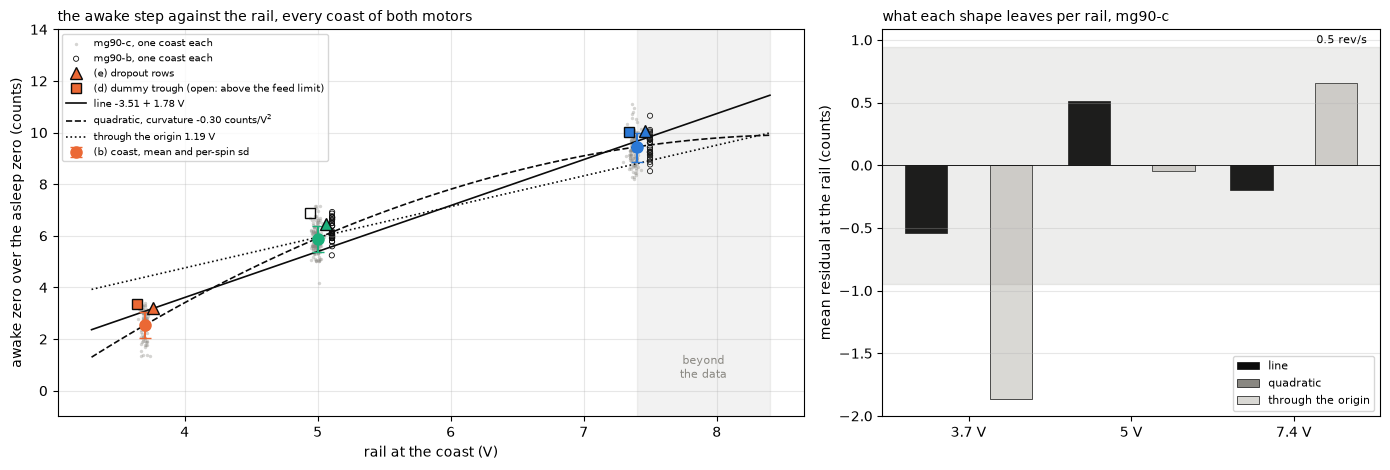

In [9]:
# the awake step against the rail: every spin, the per-rail means, and the three shapes
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [3, 2]})
a = ax[0]
oc = T[(T["motor"] == "mg90-c") & T["open_zero"].notna()]
ob = T[(T["motor"] == "mg90-b") & T["open_zero"].notna()]
rng = np.random.default_rng(0)
a.scatter(oc["rail_coast"] + rng.normal(0, 0.02, len(oc)), oc["open_zero"], s=6, color=MUTED, alpha=0.35, lw=0, label="mg90-c, one coast each")
a.scatter(ob["rail_coast"] + 0.12, ob["open_zero"], s=14, facecolors="none", edgecolors=INK, lw=0.6, label="mg90-b, one coast each")
for lv in LEVELS:
    L = LEV[lv]
    a.errorbar(lv, L["open_c"], yerr=L["open_c_sd"], fmt="o", color=RAIL_COLOR[lv], ms=8, capsize=4, lw=1.5, zorder=5,
               label="(b) coast, mean and per-spin sd" if lv == 3.7 else None)
    a.plot(lv + 0.06, L["dropout_c"], "^", color=RAIL_COLOR[lv], ms=8, mec=INK, zorder=5, label="(e) dropout rows" if lv == 3.7 else None)
    a.plot(lv - 0.06, L["trough_dummy"], "s", color=RAIL_COLOR[lv], ms=7, mec=INK, mfc="none" if L["trough_above_feed_limit"] else RAIL_COLOR[lv], zorder=5,
           label="(d) dummy trough (open: above the feed limit)" if lv == 3.7 else None)
vv = np.linspace(3.3, 8.4, 100)
a.plot(vv, F["a"] + F["b"] * vv, "-", color=INK, lw=1.2, label=f"line {F['a']:+.2f} + {F['b']:.2f} V")
a.plot(vv, np.polyval(F["quad"], vv), "--", color=INK, lw=1.2, label=f"quadratic, curvature {F['quad'][0]:+.2f} counts/V$^2$")
a.plot(vv, F["b_origin"] * vv, ":", color=INK, lw=1.2, label=f"through the origin {F['b_origin']:.2f} V")
a.axvspan(7.4, 8.4, color=MUTED, alpha=0.1)
a.text(7.9, 0.5, "beyond\nthe data", ha="center", fontsize=8, color=MUTED)
a.set_xlabel("rail at the coast (V)"); a.set_ylabel("awake zero over the asleep zero (counts)")
a.set_title("the awake step against the rail, every coast of both motors", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=7, loc="upper left")
a.set_ylim(-1, 14)
# the per-rail residual of each shape, against the 0.5 rev/s budget
a = ax[1]
x = np.arange(3)
for j, (key, lab, col) in enumerate((("per_level_resid", "line", INK), ("per_level_resid_quad", "quadratic", MUTED), ("per_level_resid_origin", "through the origin", "#d9d8d4"))):
    a.bar(x + (j - 1) * 0.26, [F[key][lv] for lv in LEVELS], 0.26, color=col, edgecolor=INK, lw=0.5, label=lab)
thr = 0.5 / rev_s_per_count("mg90-c")
a.axhspan(-thr, thr, color=MUTED, alpha=0.15); a.text(2.45, thr + 0.03, "0.5 rev/s", fontsize=8, ha="right")
a.axhline(0, color=INK, lw=0.6)
a.set_xticks(x, [f"{lv:g} V" for lv in LEVELS]); a.set_ylabel("mean residual at the rail (counts)")
a.set_title("what each shape leaves per rail, mg90-c", loc="left", fontsize=10); a.grid(alpha=0.3, axis="y"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

Left, the awake zero over the asleep zero on every coast, gray dots for mg90-c and open circles for mg90-b, with the per-rail mean and its per-spin standard deviation in the rail's color, the dropout rows as triangles and the dummy's trough as squares. The three shapes are drawn through mg90-c's coasts, and the shaded band past 7.4 V is where the 2S sag question takes them. Right, the mean residual each shape leaves at each rail, against the 0.5 rev/s budget. The thing to see is that the step is concave, 2.6 counts/V from 3.7 to 5 V and 1.5 from 5 to 7.4, so only the quadratic and the three points themselves sit inside the budget at every rail.

The awake zero sits 2.53, 5.88 and 9.43 counts over the asleep zero at 3.7, 5 and 7.4 V on mg90-c, 2.2, 5.2 and 8.3 mA, with a per-spin standard deviation of 0.5 to 0.6 counts and a standard error of 0.05 over 96, 156 and 144 coasts. mg90-b on the same board reads 6.20 and 9.49 at 5 and 7.4 V over 30 coasts each, 0.32 counts above mg90-c at 5 V (standard errors 0.07 and 0.04, different days) and 0.06 above at 7.4 V. So the step reproduces across motors and days to about 0.3 counts on this board, 0.3 mA or 0.17 rev/s. High confidence on the levels.

The shape is concave in the rail. A line through mg90-c's coasts, $-3.51\,(0.13) + 1.781\,(0.023)\,V$ counts, leaves per-rail residuals of $-0.54$, $+0.51$ and $-0.19$ counts, 11 and 13 standard errors of the coasts from zero at 3.7 and 5 V and 4 at 7.4 V, 0.27 rev/s at worst. A slope through the origin, 1.19 counts/V, leaves 1.1 counts rms. A quadratic with a curvature of $-0.30$ counts/V$^2$ leaves 0.52 counts, which is the per-spin scatter. mg90-b's two rails give 1.375 counts/V between 5 and 7.4 V against mg90-c's 1.48 over the same pair, and the dropout rows on mg90-c fit the same line within their errors. High confidence that the step is concave, moderate on its curvature, since three rails fix a quadratic with nothing left over.

The open bridge is settled from 0.1 ms after the cut: the 0.1 to 1 ms, 1 to 20 ms, 20 ms to the end and 100 to 300 ms windows read within 0.35 counts of each other at every rail, the tail 0.1 lower. No schedule on either motor streams a brake, so (c) is not measured. The capture tool's post-rung brake is a three-tick slow-decay drive whose trough feeds like (d).

The switching share is small. The dropout rows read 0.58 to 0.67 counts over the coast's open bridge, and the dummy's trough at the feeding widths 0.84 at 3.7 V and 0.57 at 7.4 V, 0.5 to 0.7 mA or 0.3 to 0.4 rev/s. So the open bridge is the driver's quiescent draw through the shunt and switching adds about 0.6 mA. At 5 V the dummy has no burst at a feeding width, and its 25 and 40 % troughs spread by a count between the bare resistor (7.2 to 7.9) and the inductive wirings (6.2 to 6.9), so the 5 V trough is known to about $\pm 0.8$ counts, as large as the share itself. The dropout rows at 3.7 and 5 V rest on three and four spins. Moderate confidence on the share, low on its size at the two lower rails. The zero stamped in each dummy burst's meta sits within about a count of (b) and (d) at all three rails, an integer with no history, so a weak check that a tracker on the board lands where the coasts do.

The asleep zero does not depend on the rail from 3.7 V up: 1205.9 to 1206.4 across the three levels, and the half count from 3.7 to 7.4 V is confounded with the sitting's drift, since every ladder ascends in rail with time. Stage 1 agrees, rest-noise at 1203 to 1204 at all three rails and the bare laps' rests at 1205 to 1206 from 3.7 to 7.6 V, and at 3.3 V the rest sits at 1189, $-16.5$ counts or 14.5 mA, 8.7 rev/s if a 3.7 V zero were kept there. The torque-off zero itself wanders across a dataset: the per-cycle baseline ranges 1.5 to 3.0 counts over 21 to 45 cycles, with slopes against the board NTC of $+1.0 \pm 0.2$, $+0.1 \pm 0.3$, $+1.1 \pm 0.3$, $+0.8 \pm 0.3$ and $-0.5 \pm 0.1$ counts/C by dataset, against opamp-temperature's 0.062 counts/C. It is not that tempco and not a consistent function of temperature. Its cause is open, and a tracker fed at every torque off follows it. At rest the frame's two shunt samples differ by 0.07 to 0.50 counts between the bridge-states sweeps, the crest below the trough, which a zero fed from the trough and subtracted from the crest carries as a systematic of up to half a count, 0.26 rev/s, low confidence from one capture family.

## The tracker replayed over the captures

The port first. Integer arithmetic as specified, a feed moving the fed zero by $((x \ll 16) - z) \gg 13$, the other zero's stale counter aging on every tick, and a stale zero moving by the same delta. The checks below run the port's arithmetic through a seed, a constant feed, a step closing 63.2 % in one time constant and 100 % in eleven, and a stale zero following the other's move.

In [10]:
ASLEEP, COAST, DRIVE = 0, 1, 2            # bridge states; the brake is a 3-tick DRIVE
K_NONE, K_ASLEEP, K_AWAKE = -1, 0, 1      # which zero a tick feeds


@nb.njit
def run_tracker(kind, sample, awake_q, asleep_q, awake_fresh, asleep_fresh, out_awake, out_asleep):
    # the tick loop: a feed moves its zero by ((sample << 16) - zero) >> 13 (an arithmetic shift, so it floors), ages the
    # other zero's counter, and once that one is stale moves it by the same delta; a tick with no feed ages both
    for i in range(kind.shape[0]):
        k = kind[i]
        if k == 1:
            delta = ((np.int64(sample[i]) << 16) - awake_q) >> 13
            awake_q += delta
            if asleep_fresh > 1:
                asleep_fresh -= 1
            else:
                asleep_fresh = 0
                asleep_q += delta
            awake_fresh = 65535
        elif k == 0:
            delta = ((np.int64(sample[i]) << 16) - asleep_q) >> 13
            asleep_q += delta
            if awake_fresh > 1:
                awake_fresh -= 1
            else:
                awake_fresh = 0
                awake_q += delta
            asleep_fresh = 65535
        else:
            if awake_fresh > 0:
                awake_fresh -= 1
            if asleep_fresh > 0:
                asleep_fresh -= 1
        out_awake[i] = awake_q
        out_asleep[i] = asleep_q
    return awake_q, asleep_q, awake_fresh, asleep_fresh


@nb.njit
def rail_ewma(kind, rail, state, out):
    # a float EWMA of the rail at the same gain, fed on the awake-fed ticks only and held otherwise: the rail the awake
    # zero's value was learned at, method B's extra state
    a = 1.0 / (1 << 13)
    for i in range(kind.shape[0]):
        if kind[i] == 1:
            state += a * (rail[i] - state)
        out[i] = state
    return state


def counts(q):
    # the rounded output, as a reading would subtract it
    return np.maximum((np.asarray(q, np.int64) + (1 << (FRAC - 1))) >> FRAC, 0)


def q_to_float(q):
    return np.asarray(q, np.float64) / (1 << FRAC)


class Tracker:
    def __init__(self):
        self.awake_q = self.asleep_q = np.int64(0)
        self.awake_fresh = self.asleep_fresh = np.int64(0)

    def seed(self, c):
        # the boot seed: both zeros at the rest measurement, the step unknown
        self.awake_q = np.int64(int(c)) << FRAC
        self.asleep_q = self.awake_q

    def run(self, kind, sample):
        out_a, out_s = np.empty(len(kind), np.int64), np.empty(len(kind), np.int64)
        self.awake_q, self.asleep_q, self.awake_fresh, self.asleep_fresh = run_tracker(
            kind.astype(np.int8), np.asarray(sample).astype(np.int64), self.awake_q, self.asleep_q, self.awake_fresh, self.asleep_fresh, out_a, out_s)
        return out_a, out_s


def kinds_from_bridge(bridge, ticks):
    # the feed kind per tick from the bridge state and the drive width: a drive at <= 240 ticks feeds the awake zero at once,
    # a rest feeds the asleep zero and a coast the awake zero once 32 ticks past the last change, anything else feeds nothing
    n = len(bridge)
    change = np.ones(n, bool)
    change[1:] = bridge[1:] != bridge[:-1]
    idx = np.arange(n)
    since = idx - np.maximum.accumulate(np.where(change, idx, 0))
    kind = np.full(n, K_NONE, np.int8)
    kind[(bridge == DRIVE) & (ticks > 0) & (ticks <= TROUGH_FEED_MAX_TICKS)] = K_AWAKE
    settled = since >= ZERO_SETTLE_TICKS
    kind[(bridge == ASLEEP) & settled] = K_ASLEEP
    kind[(bridge == COAST) & settled] = K_AWAKE
    return kind


# the port's arithmetic checked: a seed held, 63.2 % of a step at one tau and all of it by eleven, a stale zero following
TAU = 1 << ALPHA_SHIFT
t = Tracker(); t.seed(2048)
a_, s_ = t.run(np.full(4 * TAU, K_AWAKE, np.int8), np.full(4 * TAU, 2048))
assert (counts(a_) == 2048).all()
for frm, to in ((2048, 2088), (2088, 2048), (0, 2048)):
    t = Tracker(); t.seed(frm)
    a_, s_ = t.run(np.full(TAU, K_AWAKE, np.int8), np.full(TAU, to))
    assert abs(int(counts(a_[-1])) - (frm + ((to - frm) * 632) // 1000)) <= 1
    a_, s_ = t.run(np.full(11 * TAU, K_AWAKE, np.int8), np.full(11 * TAU, to))
    assert counts(a_[-1]) == to
t = Tracker(); t.seed(460)
t.run(np.full(64, K_ASLEEP, np.int8), np.full(64, 460))
a_, s_ = t.run(np.full(12 * TAU, K_AWAKE, np.int8), np.full(12 * TAU, 470))
assert counts(a_[-1]) == 470 and counts(s_[-1]) == 460
a_, s_ = t.run(np.full(STALE_TICKS, K_ASLEEP, np.int8), np.full(STALE_TICKS, 460))
assert counts(a_[-1]) == 470                                   # not yet stale: the awake zero holds
a_, s_ = t.run(np.full(12 * TAU, K_ASLEEP, np.int8), np.full(12 * TAU, 260))
assert counts(a_[-1]) == 270 and counts(s_[-1]) == 260         # stale: it followed the asleep zero's move
print(f"the port holds its checks; tau {TAU_S:.3f} s, a feed at <= {TROUGH_FEED_MAX_TICKS} ticks ({TROUGH_FEED_MAX_TICKS / ARR * 100:.0f} % duty), the brake {BRAKE_TICKS} ticks")

the port holds its checks; tau 0.410 s, a feed at <= 240 ticks (20 % duty), the brake 3 ticks


The replay builds each dataset tick by tick from the records, runs the port once through it, and reads the awake zero at every spin.

In [11]:
NOISE_TROUGH = 1.0                 # counts rms on the synthetic trough: the dummy's trough band reads 0.2 to 0.9 per burst
PRE_DRIVE_COAST_S = 0.005          # torque on to the stream's first row, segments.csv


def per_rail_open(recs, motor):
    # the dataset's own open-bridge zero per rail (the mean over its spins), the truth; the motor-wide level fills a rail it lacks
    acc = {}
    for r in recs:
        for s in r["segs"]:
            if s["cmd"] != 0 and "open_zero" in s:
                acc.setdefault(r["level"], []).append(s["open_zero"])
    out = {k: float(np.mean(v)) for k, v in acc.items()}
    for lv in LEVELS:
        out.setdefault(lv, LEV[lv]["open_c"] if motor == "mg90-c" or not np.isfinite(LEV[lv]["open_b"]) else LEV[lv]["open_b"])
    return out


D_MINUS_B = float(np.mean([LEV[lv]["trough_dummy"] - LEV[lv]["open_c"] for lv in LEVELS if not LEV[lv]["trough_above_feed_limit"]]))


def trough_level(level, mode, motor, own_open):
    # the level a feeding width's trough is synthesized at: (d) the dummy's trough where a feeding width was measured, else the
    # open bridge plus the mean (d) - (b); (e) the dropout rows; (b) the open bridge itself
    L = LEV[level]
    if mode == "d":
        return own_open + (D_MINUS_B if L["trough_above_feed_limit"] else L["trough_dummy"] - L["open_c"])
    if mode == "e":
        use_b = motor == "mg90-b" and np.isfinite(L["dropout_b"])
        return own_open + ((L["dropout_b"] if use_b else L["dropout_c"]) - (L["open_b"] if use_b else L["open_c"]))
    return own_open


def chain_gap_default():
    # a coast's end to the next chain's first row where segments.csv exists, for the dataset without one
    gaps = []
    for r in reduce_dataset("mg90-c", "capture-1"):
        S = r["segs"]
        gaps += [S[i]["t_start"] - S[i - 1]["t_end"] for i in range(1, len(S)) if S[i - 1]["cmd"] == 0 and S[i]["cmd"] != 0 and np.isfinite(S[i]["t_start"])]
    return float(np.median(gaps))


def synth_times(recs, gap):
    # segments.csv's stand-in: back to back within a chain, the median chain gap between chains, from the cycle's start
    for r in recs:
        t, prev_cmd = r["t_start"] + 0.09, None
        for s in r["segs"]:
            if prev_cmd == 0 and s["seg"] > 1:
                t += gap
            elif prev_cmd is not None:
                t += PRE_DRIVE_COAST_S
            s["t_start"], s["t_end"] = t, t + s["n"] / FS
            t, prev_cmd = s["t_end"], s["cmd"]
    return recs


def build_cycle(r, prev_end, next_start, zero_rest, own_open, tr_level, brake_s, rng):
    # one cycle's per-tick bridge state, drive ticks, shunt samples and rail, plus the rest after it, and each segment's row span
    bridge, ticks, samples, rails, marks = [], [], [], [], {}
    n_at = 0

    def push(b, tk, smp, rail=None):
        nonlocal n_at
        n = len(smp)
        bridge.append(np.full(n, b, np.int8)); ticks.append(np.full(n, tk, np.int16) if np.isscalar(tk) else tk)
        samples.append(smp); rails.append(np.full(n, r["rail_rest"], np.float32) if rail is None else rail)
        n_at += n

    def noise(level, sd, n):
        return np.floor(level + sd * rng.standard_normal(n) + 0.5).astype(np.int32)   # integer codes about a level

    S = r["segs"]
    n_gap = max(int(round((S[0]["t_start"] - prev_end) * FS)), 0) if np.isfinite(prev_end) else 2 * FS
    push(ASLEEP, 0, noise(zero_rest, NOISE_REST, n_gap))                          # the rest before the baseline
    for i, s in enumerate(S):
        if i > 0:
            gap = max(int(round((s["t_start"] - S[i - 1]["t_end"]) * FS)), 0)
            if S[i - 1]["cmd"] == 0 and S[i - 1]["seg"] != 0 and s["cmd"] != 0:
                nb_, nc = int(round(brake_s * FS)), int(round(PRE_DRIVE_COAST_S * FS))   # a chain's end: brake, torque off, the pre-drive coast
                push(DRIVE, BRAKE_TICKS, noise(tr_level, NOISE_TROUGH, nb_))
                push(ASLEEP, 0, noise(zero_rest, NOISE_REST, max(gap - nb_ - nc, 0)))
                push(COAST, 0, noise(own_open, NOISE_REST, nc))
            else:
                push(COAST, 0, noise(own_open, NOISE_REST, gap))                   # after the baseline, or within a chain
        marks[s["seg"]] = (n_at, n_at + s["n"])
        tk, raw, rail = s["ticks"].astype(np.int16), s["raw"].astype(np.int32), BOARD.rail_v(s["vbus"]).astype(np.float32)
        if s["seg"] == 0:
            push(ASLEEP, 0, raw, rail)                                              # the baseline's real rows
        else:
            feed = (tk > 0) & (tk <= TROUGH_FEED_MAX_TICKS)
            smp = raw.copy()
            smp[feed] = noise(tr_level, NOISE_TROUGH, int(feed.sum()))              # the trough the stream did not carry
            bridge.append(np.where(tk > 0, DRIVE, COAST).astype(np.int8)); ticks.append(tk); samples.append(smp); rails.append(rail)
            n_at += len(tk)
    nb_ = int(round(brake_s * FS))
    push(DRIVE, BRAKE_TICKS, noise(tr_level, NOISE_TROUGH, nb_))                    # the last chain's brake
    end = next_start - PRE_DRIVE_COAST_S if np.isfinite(next_start) else S[-1]["t_end"] + 2.0
    n_rest = max(int(round((end - S[-1]["t_end"]) * FS)) - nb_, 0)
    push(ASLEEP, 0, noise(zero_rest, NOISE_REST, n_rest))                           # torque off to the next cycle
    return np.concatenate(bridge), np.concatenate(ticks), np.concatenate(samples), np.concatenate(rails), marks, S[-1]["t_end"] + (nb_ + n_rest) / FS


def simulate(motor, name, mode="d", brake_s=BRAKE_POLL_S, trace_every=0, rng_seed=1):
    # the tracker through one dataset in time order, seeded at its first baseline: one row per spin, and a decimated trace if asked
    recs = reduce_dataset(motor, name)
    if not np.isfinite(recs[0]["segs"][0]["t_start"]):
        recs = synth_times(recs, chain_gap_default())
    opens = per_rail_open(recs, motor)
    rng = np.random.default_rng(rng_seed)
    t = Tracker()
    t.seed(round(recs[0]["zero_i"]))
    rows, trace = [], []
    prev_end, prev_level, tick0 = np.nan, None, 0
    last_feed_rail, rail_state = recs[0]["rail_rest"], float(recs[0]["rail_rest"])
    rpc = rev_s_per_count(motor)
    first_chain = {s["seg"] for s in recs[0]["segs"][:next(i for i, s in enumerate(recs[0]["segs"]) if s["seg"] > 0 and s["cmd"] == 0) + 1]}
    for ci, r in enumerate(recs):
        own_open = r["zero_i"] + opens[r["level"]]
        tr = trough_level(r["level"], mode, motor, own_open)
        zero_rest = r["zero_i"] if ci == 0 else 0.5 * (r["zero_i"] + recs[ci - 1]["zero_i"])   # the rest between two cycles
        next_start = recs[ci + 1]["segs"][0]["t_start"] if ci + 1 < len(recs) else np.nan
        bridge, ticks, samples, rails, marks, prev_end = build_cycle(r, prev_end, next_start, zero_rest, own_open, tr, brake_s, rng)
        kind = kinds_from_bridge(bridge, ticks)
        aw, sl = t.run(kind, samples)
        aw, sl = q_to_float(aw), q_to_float(sl)
        rl = np.empty(len(kind), np.float64)
        rail_state = rail_ewma(kind, rails.astype(np.float64), rail_state, rl)
        fed_awake = np.flatnonzero(kind == 1)
        if trace_every:
            idx = np.arange(0, len(aw), trace_every)
            trace.append(pd.DataFrame(dict(t_s=(tick0 + idx) / FS, awake=aw[idx] - recs[0]["zero_i"], asleep=sl[idx] - recs[0]["zero_i"],
                                           truth=own_open - recs[0]["zero_i"], level=r["level"], bridge=bridge[idx], k=r["k"])))
        tick0 += len(aw)
        for i, s in enumerate(r["segs"]):
            if s["cmd"] == 0:
                continue
            a, b = marks[s["seg"]]
            prev_feeds = fed_awake[fed_awake < a]
            if len(prev_feeds):
                last_feed_rail = float(rails[prev_feeds[-1]])                        # the rail at the last awake-fed tick
            truth = r["zero_i"] + opens[r["level"]]
            rows.append(dict(motor=motor, name=name, k=r["k"], level=r["level"], duty=r["duty"], kick=r["kick"], seg=s["seg"], dir=s["dir"],
                             ticks=s["ticks_held"], feeds=s["ticks_held"] <= TROUGH_FEED_MAX_TICKS, is_hold=r["segs"][i - 1]["cmd"] != 0,
                             first_chain=ci == 0 and s["seg"] in first_chain, dur_s=s["n"] / FS,
                             first_after_rail_change=prev_level is not None and prev_level != r["level"] and s["seg"] == next(q["seg"] for q in r["segs"] if q["cmd"] != 0),
                             t_s=(tick0 - len(aw) + a) / FS, zero_i=r["zero_i"], truth=truth, truth_own=r["zero_i"] + s["open_zero"] if "open_zero" in s else np.nan,
                             rail_spin=s["rail_spin"], rail_last_feed=last_feed_rail, rail_ewma_start=rl[a], rail_ewma_200=rl[b - N200:b].mean(),
                             awake_start=aw[a], awake_end=aw[b - 1], awake_200=aw[b - N200:b].mean(),
                             asleep_start=sl[a], asleep_end=sl[b - 1], asleep_200=sl[b - N200:b].mean(), mode=mode, brake_s=brake_s, rpc=rpc))
        prev_level = r["level"]
    df = pd.DataFrame(rows)
    for c in ("start", "end", "200"):
        df[f"err_{c}"] = df[f"awake_{c}"] - df["truth"]
        df[f"err_{c}_ma"] = df[f"err_{c}"] * MA_PER_COUNT
        df[f"err_{c}_rev_s"] = df[f"err_{c}"] * df["rpc"]
    df["err_200_own"] = df["awake_200"] - df["truth_own"]
    return (df, pd.concat(trace, ignore_index=True)) if trace_every else df


# the primary replay (the dummy's trough level, the brake 20 ms) with traces for two datasets, then every variant
frames, TRACE = [], {}
for motor, name in SIM:
    for mode in ("d", "e", "b"):
        for brake_s in (BRAKE_POLL_S, BRAKE_POLL_S * BRAKE_POLLS):
            if mode == "d" and brake_s == BRAKE_POLL_S and name in ("capture-1", "low-meter-3") and motor == "mg90-c":
                df, TRACE[name] = simulate(motor, name, mode, brake_s, trace_every=400)   # 50 Hz, for the timeline figure
            else:
                df = simulate(motor, name, mode, brake_s)
            frames.append(df)
Q2 = pd.concat(frames, ignore_index=True)
P = Q2[(Q2["mode"] == "d") & (Q2["brake_s"] == BRAKE_POLL_S)]                       # the primary replay
print(f"{len(P)} spins replayed per variant, {int((~P['first_chain']).sum())} of them warm; mg90-b's chain gaps synthesized at {chain_gap_default():.1f} s")

456 spins replayed per variant, 449 of them warm; mg90-b's chain gaps synthesized at 12.0 s


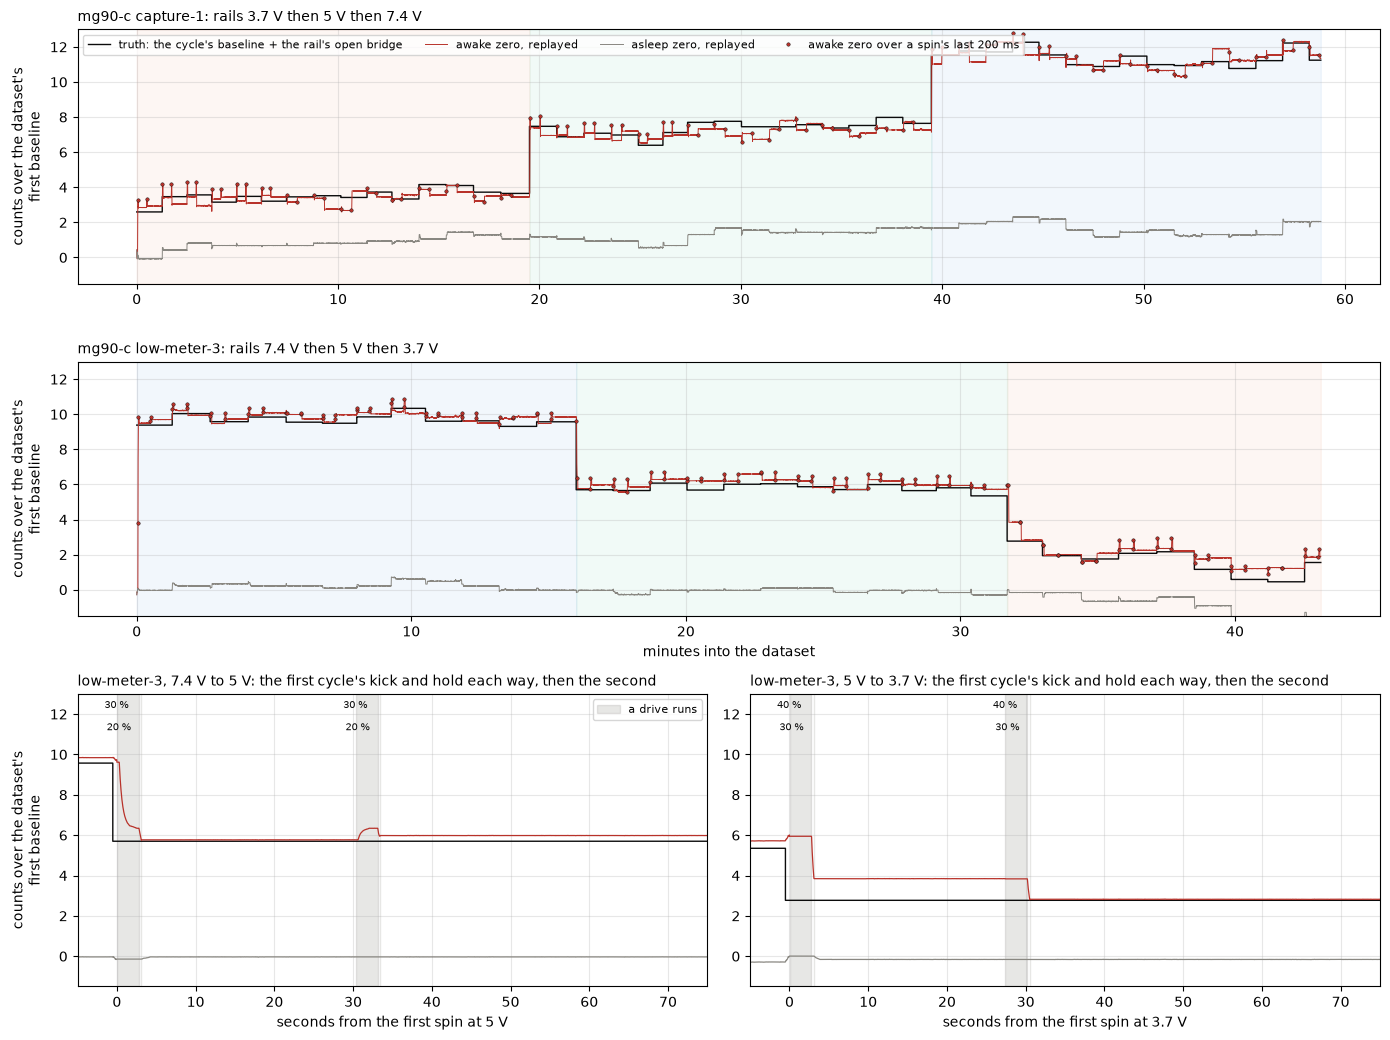

In [12]:
# the awake zero through two datasets' timelines against the per-rail truth, and low-meter-3's two rail steps up close
fig = plt.figure(figsize=(14, 10.5))
gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.15])
axes = [fig.add_subplot(gs[0, :]), fig.add_subplot(gs[1, :])]
for a, name in zip(axes, ("capture-1", "low-meter-3")):
    tr = TRACE[name]
    t_min = tr["t_s"] / 60
    for lv in LEVELS:
        g = tr[tr["level"] == lv]
        if len(g):
            a.fill_between(g["t_s"] / 60, -1.5, 13, color=RAIL_COLOR[lv], alpha=0.06, step="mid")
    a.step(t_min, tr["truth"], where="post", color=INK, lw=1.0, label="truth: the cycle's baseline + the rail's open bridge")
    a.plot(t_min, tr["awake"], color=RED, lw=0.7, label="awake zero, replayed")
    a.plot(t_min, tr["asleep"], color=MUTED, lw=0.7, label="asleep zero, replayed")
    sp = P[(P["name"] == name) & (P["motor"] == "mg90-c")]
    a.plot(sp["t_s"] / 60, sp["awake_200"] - sp["zero_i"].iloc[0], "o", ms=2.5, color=RED, mec=INK, mew=0.3, label="awake zero over a spin's last 200 ms")
    a.set_ylim(-1.5, 13); a.set_ylabel("counts over the dataset's\nfirst baseline"); a.grid(alpha=0.3)
    a.set_title(f"mg90-c {name}: rails {' then '.join(f'{lv:g} V' for lv in pd.unique(tr['level']))}", loc="left", fontsize=10)
axes[0].legend(fontsize=8, loc="upper left", ncol=4)
axes[1].set_xlabel("minutes into the dataset")
# the two rail steps of low-meter-3: from 5 s before the new rail's first spin to 75 s after, the drives shaded, each rung's duty on top
tr = TRACE["low-meter-3"]
sp = P[(P["name"] == "low-meter-3") & (P["motor"] == "mg90-c")]
for j, (lv_from, lv_to) in enumerate(((7.4, 5.0), (5.0, 3.7))):
    a = fig.add_subplot(gs[2, j])
    t0 = sp[sp["level"] == lv_to]["t_s"].iloc[0]
    g = tr[(tr["t_s"] >= t0 - 5) & (tr["t_s"] <= t0 + 75)]
    a.fill_between(g["t_s"] - t0, -1.5, 13, where=g["bridge"].to_numpy() == DRIVE, color=MUTED, alpha=0.2, step="mid", label="a drive runs")
    a.step(g["t_s"] - t0, g["truth"], where="post", color=INK, lw=1.0)
    a.plot(g["t_s"] - t0, g["awake"], color=RED, lw=0.9)
    a.plot(g["t_s"] - t0, g["asleep"], color=MUTED, lw=0.9)
    for _, r in sp[(sp["t_s"] >= t0 - 5) & (sp["t_s"] <= t0 + 75)].iterrows():
        kick = not r["is_hold"] and r["kick"] > 0
        a.annotate(f"{r['kick'] if kick else r['duty']} %", (r["t_s"] - t0, 12.3 if kick else 11.2), fontsize=7, ha="center", color=INK)
    a.set_xlim(-5, 75); a.set_ylim(-1.5, 13); a.grid(alpha=0.3); a.set_xlabel(f"seconds from the first spin at {lv_to:g} V")
    a.set_title(f"low-meter-3, {lv_from:g} V to {lv_to:g} V: the first cycle's kick and hold each way, then the second", loc="left", fontsize=10)
    if j == 0:
        a.set_ylabel("counts over the dataset's\nfirst baseline"); a.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

The replayed zeros through capture-1 (top) and low-meter-3 (middle), 50 Hz samples of the tick-exact run, the rail as the background tint and the truth as the black step: each cycle's own baseline plus the rail's open-bridge level. The gray trace is the asleep zero, which follows the baseline's wander, and the red one the awake zero, with its value over each spin's last 200 ms as dots. The thing to see is the awake zero jumping to the new rail's level inside the first cycle after a rail step when that cycle's rungs feed it (capture-1, at 15 %), and holding the old rail's level through a whole kick and hold when they do not. The bottom row is low-meter-3's two rail steps up close, the drives shaded and each rung's duty on top: at 7.4 to 5 V the 30 % kick runs 3.9 counts high until the 20 % hold learns the step, and at 5 to 3.7 V the 30 % kick and the 30 % hold feed nothing, so the first spin runs its whole 2.8 s at the old level and the coasts between the chains close the gap by about half each.

In [13]:
def summarize(DD, by):
    # rms and worst of the error per group at the first row and over the last 200 ms, in counts and rev/s, with the count past 0.5 rev/s
    rows = []
    for key, g in DD.groupby(by, sort=False):
        rows.append(dict(**dict(zip(by, key if isinstance(key, tuple) else (key,))), spins=len(g),
                         rms_start=np.sqrt((g["err_start"] ** 2).mean()), worst_start=g["err_start"].abs().max(),
                         rms_200=np.sqrt((g["err_200"] ** 2).mean()), worst_200=g["err_200"].abs().max(), mean_200=g["err_200"].mean(),
                         rms_200_rev_s=np.sqrt((g["err_200_rev_s"] ** 2).mean()), worst_200_rev_s=g["err_200_rev_s"].abs().max(),
                         over_half_200=int((g["err_200_rev_s"].abs() > 0.5).sum()), over_half_start=int((g["err_start"] * g["rpc"]).abs().gt(0.5).sum()),
                         rms_200_own=np.sqrt((g["err_200_own"] ** 2).mean())))
    return pd.DataFrame(rows)


W = P[~P["first_chain"]]                                                        # warm: the dataset's first chain left out
SUMW = summarize(W, ["motor", "name"])
SUMW.loc[len(SUMW)] = summarize(W.assign(motor="all", name="pooled"), ["motor", "name"]).iloc[0]
print("primary replay per dataset, warm (counts over the truth; start = the spin's first row, 200 = its last 200 ms)")
print(SUMW.round(2).to_string(index=False))
SUMALL = summarize(P.assign(motor="all", name="pooled"), ["motor", "name"]).iloc[0]
print(f"\nevery spin, the boot chains included: rms 200 {SUMALL['rms_200']:.2f}, worst {SUMALL['worst_200']:.2f}, rms start {SUMALL['rms_start']:.2f}, worst {SUMALL['worst_start']:.2f}")
# the sensitivity to the trough level fed and to the brake's length, pooled warm
SENS = summarize(Q2[~Q2["first_chain"]], ["mode", "brake_s"])
print("\nthe variants, pooled warm: mode d = the dummy's trough, e = the dropout rows, b = the open bridge itself")
print(SENS.round(2).to_string(index=False))
# the feeding and the non-feeding rungs, warm: what each converges to
fe = W[W["feeds"] & (W["dur_s"] >= 1.0)]
FR = fe.groupby(["motor", "name", "level", "duty", "is_hold"])["err_end"].agg(["mean", "std", "size"])
print(f"\nfeeding rungs (<= 20 %, held >= 1 s), warm, per rung: the awake zero at the rung's end {FR['mean'].min():+.2f} to {FR['mean'].max():+.2f} counts over the truth, "
      f"sd across a rung's spins {FR['std'].min():.2f} to {FR['std'].max():.2f}; by rail " + ", ".join(f"{lv:g} V {g['err_end'].mean():+.2f}" for lv, g in fe.groupby("level")))
nf = W[~W["feeds"]]
NF = nf.groupby(["motor", "name"], sort=False)["err_200"].agg(["mean", "std", lambda x: x.abs().max()])
print("non-feeding rungs (> 20 %), warm, per dataset, mean / sd / worst counts: " + ", ".join(f"{m} {n} {r['mean']:+.2f} / {r['std']:.2f} / {r.iloc[2]:.2f}" for (m, n), r in NF.iterrows()))
bad = W[W["err_200_rev_s"].abs() > 0.5]
print(f"\nwarm spins past 0.5 rev/s over their last 200 ms ({len(bad)} of {len(W)}):")
print(bad[["motor", "name", "k", "level", "duty", "kick", "seg", "dir", "ticks", "feeds", "first_after_rail_change", "dur_s", "err_start", "err_200", "err_200_rev_s"]].round(2).to_string(index=False))
FC = P[P["first_chain"]]
print("\nthe first chain of each dataset, seeded at its baseline (the boot case):")
print(FC[["motor", "name", "level", "duty", "seg", "ticks", "feeds", "dur_s", "err_start", "err_end", "err_200", "err_200_rev_s"]].round(2).to_string(index=False))

primary replay per dataset, warm (counts over the truth; start = the spin's first row, 200 = its last 200 ms)
 motor        name  spins  rms_start  worst_start  rms_200  worst_200  mean_200  rms_200_rev_s  worst_200_rev_s  over_half_200  over_half_start  rms_200_own
mg90-c   capture-1     89       0.68         4.08     0.49       0.95      0.13           0.26             0.50              1                3         0.67
mg90-c   capture-2     89       0.62         3.82     0.46       0.78      0.14           0.24             0.41              0                2         0.71
mg90-c       low-1     82       0.54         4.00     0.51       2.29      0.33           0.27             1.21              1                2         0.68
mg90-c low-meter-3    130       0.72         3.92     0.72       3.92      0.51           0.38             2.08              5                6         0.93
mg90-b   capture-1     59       0.53         3.08     0.43       0.72      0.09           0.23           

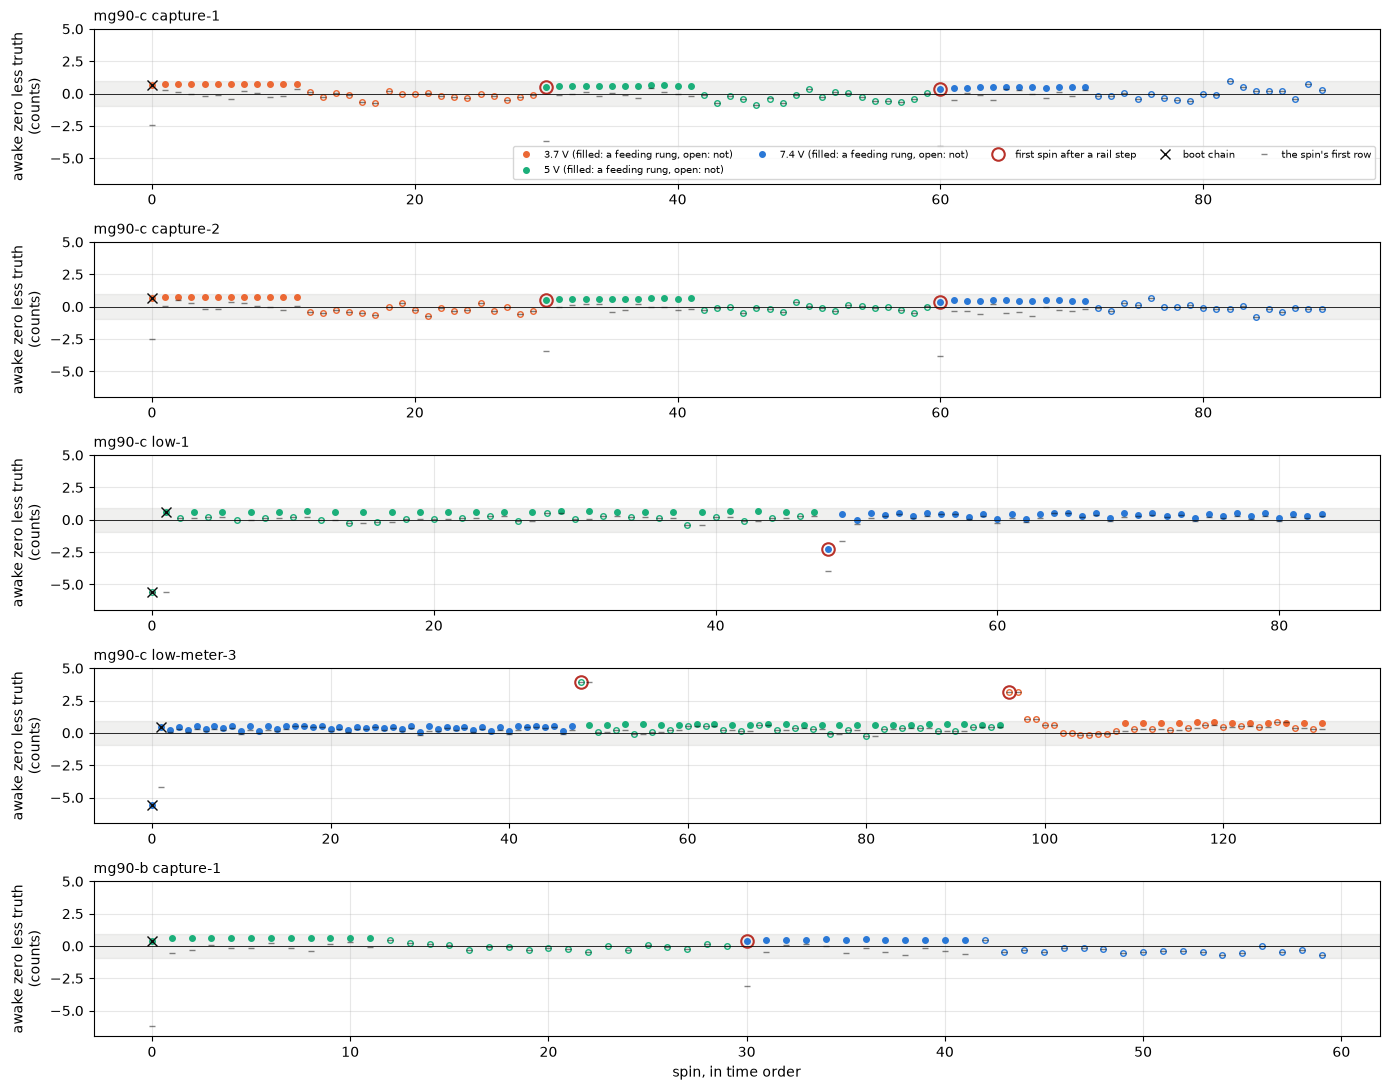

In [14]:
# every spin's error over its last 200 ms, by dataset: feeding rungs filled, non-feeding open, the first spin after a rail step ringed
fig, ax = plt.subplots(5, 1, figsize=(14, 11), sharex=False)
for a, (motor, name) in zip(ax, SIM):
    g = P[(P["motor"] == motor) & (P["name"] == name)].reset_index(drop=True)
    thr = 0.5 / g["rpc"].iloc[0]
    a.axhspan(-thr, thr, color=MUTED, alpha=0.12)
    for lv in LEVELS:
        h = g[g["level"] == lv]
        if not len(h):
            continue
        a.plot(h.index[h["feeds"]], h["err_200"][h["feeds"]], "o", ms=4, color=RAIL_COLOR[lv], label=f"{lv:g} V (filled: a feeding rung, open: not)")
        a.plot(h.index[~h["feeds"]], h["err_200"][~h["feeds"]], "o", ms=4, mfc="none", color=RAIL_COLOR[lv])
    rc = g[g["first_after_rail_change"]]
    a.plot(rc.index, rc["err_200"], "o", ms=9, mfc="none", mec=RED, mew=1.5, label="first spin after a rail step")
    fc = g[g["first_chain"]]
    a.plot(fc.index, fc["err_200"], "x", ms=7, color=INK, label="boot chain")
    a.plot(g.index, g["err_start"], "_", ms=5, color=INK, alpha=0.5, label="the spin's first row")
    a.axhline(0, color=INK, lw=0.6); a.grid(alpha=0.3)
    a.set_ylabel("awake zero less truth\n(counts)"); a.set_title(f"{motor} {name}", loc="left", fontsize=10)
    a.set_ylim(-7, 5)
ax[0].legend(fontsize=7, ncol=5, loc="lower right"); ax[-1].set_xlabel("spin, in time order")
plt.tight_layout(); plt.show()

Every spin of the primary replay, the awake zero less the truth over the spin's last 200 ms, in the rail's color, filled where the rung feeds the awake zero (20 % or under) and open where it does not, with the error at the spin's first row as a tick, the first spin after each rail step ringed in red, the boot chain crossed, and the 0.5 rev/s band in gray. The thing to see is where the dots leave the band: at the boot chains, at the rail steps, and nowhere else.

Replayed tick-exactly over the five datasets, the tracker holds the awake zero within 0.56 counts rms (0.30 rev/s) over a spin's last 200 ms once warm, 0.94 at the first row with the boot chains in, and 0.67 rms over every spin. 7 of 449 warm spins exceed 0.5 rev/s over their last 200 ms, 14 at their first row, and every one is a rail step or a boot.

- A feeding rung converges within the spin to the trough level it is fed. At its end the awake zero sits $+0.45$ to $+0.79$ counts over the open-bridge truth, by rung, with a standard deviation of 0.04 or under across a rung's spins. That offset is the modeled (d) minus (b). Fed with (e) it is $+0.6$, with (b) zero. So a long hold is as good as its trough level, and the trough's own offset against the coast zero, 0.4 to 0.8 counts or 0.2 to 0.4 rev/s, is what remains. Low to moderate confidence on that residual, since the motor's trough was never streamed.
- A non-feeding rung holds what the last coast or feeding rung left: per dataset a warm mean of $-0.20$ to $+0.49$ counts and a standard deviation of 0.20 to 0.82, pooled $+0.00$ and 0.54, worst 3.92.
- The first spin after a rail step. At 20 % or under (capture-1 and capture-2 at 5 and 7.4 V, mg90-b at 7.4 V) the first row reads $-3.4$ to $-4.1$ counts, 1.8 to 2.2 rev/s, and the spin learns the step inside itself, 97 % of it by 1.5 s, ending $+0.35$ to $+0.5$. With a 300 ms kick at 240 ticks then a hold at 96 (low-1, 5 to 7.4 V) the first row reads $-4.0$, the kick's last 200 ms $-2.29$ (1.2 rev/s), and the hold closes it. Above 20 % nothing feeds: low-meter-3's 7.4 to 5 V step under a 30 % kick carries $+3.92$ counts (2.1 rev/s) through the whole kick before the 20 % hold learns, and its 5 to 3.7 V step under a 30 % kick and a 30 % hold runs the whole first spin at $+3.17$ counts (1.68 rev/s) for 2.8 s. The same cycle's reverse spin reads $+1.06$ (0.56 rev/s) after one 0.3 s coast and a 20 ms brake, the second cycle $+0.60$, the third $-0.17$: the error decays by the coasts alone, about half per 0.3 s coast.
- Boot, each dataset's first chain with the step unknown: the first row reads $-2.5$ counts at 3.7 V, $-5.6$ and $-6.2$ at 5 V and $-9.3$ at 7.4 V, 1.3 to 5.0 rev/s. low-1's 30 % kick carries $-5.62$ for its whole 300 ms. low-meter-3's 20 % kick feeds and closes to $-4.2$ by its end, and the hold finishes it.
- No stage 2 dataset reaches 3.3 V. From stage 1's rests a step from 3.7 V down to 3.3 V moves the asleep zero $-16.5$ counts, and a fresh awake zero follows only once stale or fed, so a drive within 3.3 s of such a step would read 14.5 mA (8.7 rev/s) high. The rule that a 1S rail under 3.7 V is ungraded stands.
- Sensitivity. With the brake at 1 s the (d) and (e) replays get slightly worse, 0.67 and 0.59 counts rms pooled warm, since the brake feeds the trough level longer, and the (b) replay much better, 0.31 with its worst 3.57 at the rail steps only. (e) in place of (d) moves the numbers by under 0.05 counts rms, and (b) lowers them by 0.1 to 0.2. Against each spin's own coast zero as the truth every rms rises by about 0.3 counts, the per-spin scatter.

## Convergence and rail steps

How many seconds of feed a step of the measured size takes on the exact port, what each kind of segment closes, and what a 2S pack's sag during a hold above 20 % would move the true zero by, where nothing feeds.

settling within 0.5 counts under continuous feed, tau 0.410 s
         step  counts    ma  rev_s  settle_s_exact  settle_s_analytic  left_after_0p8s_counts
   3.7 -> 5 V    3.35  2.95   1.77            0.82               0.78                    0.47
   5 -> 7.4 V    3.55  3.13   1.88            0.85               0.80                    0.50
 3.7 -> 7.4 V    6.90  6.08   3.65            1.13               1.07                    0.98
 7.4 -> 3.7 V   -6.90 -6.08  -3.65            1.03               1.07                   -0.98
boot at 3.7 V    2.53  2.23   1.34            0.71               0.66                    0.36
  boot at 5 V    5.88  5.18   3.12            1.06               1.01                    0.83
boot at 7.4 V    9.43  8.31   5.00            1.25               1.20                    1.34

the fraction of a step one segment's feed closes
                          segment  seconds  fraction_closed  left_of_3p55_counts
        coast 0.3 s (low-meter-3)     0.30            0

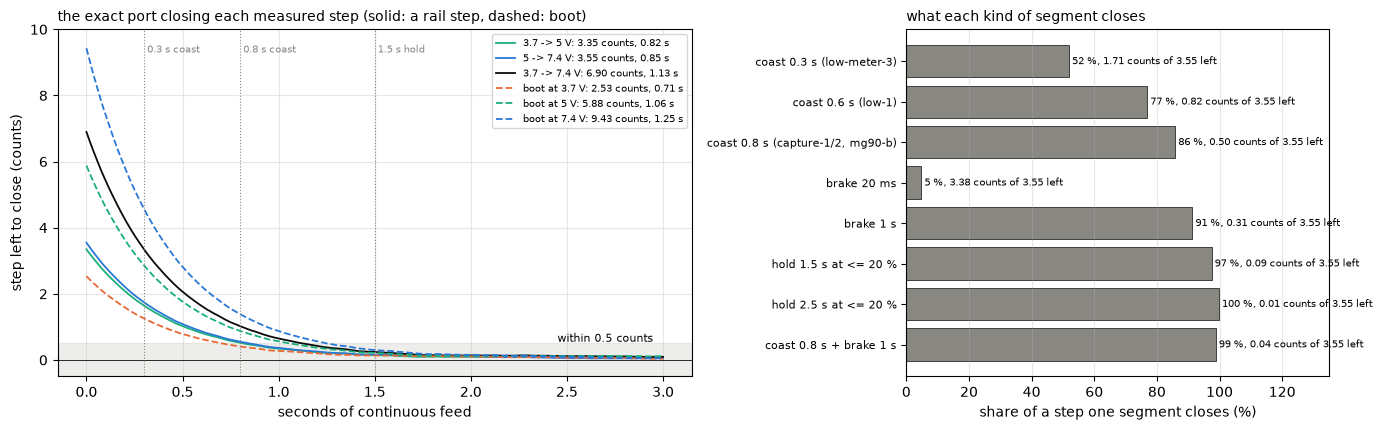

In [15]:
def settle_ticks(step_counts, within=0.5, base=1206):
    # ticks of continuous feed until the port sits within `within` counts of a target `step` away; integer samples whose
    # mean is the target (the rest floor's dither), the input the board has
    t = Tracker(); t.seed(base)
    target, n = base + step_counts, int(20 * FS)
    rng = np.random.default_rng(0)
    smp = np.floor(target + 1.08 * rng.standard_normal(n) + 0.5).astype(np.int64)
    a_, _ = t.run(np.full(n, K_AWAKE, np.int8), smp)
    err = np.abs(q_to_float(a_) - target)
    bad = np.flatnonzero(err > within)
    return (int(bad[-1] + 1) if len(bad) else 0), q_to_float(a_) - target


RPC = rev_s_per_count("mg90-c")
oc_ = {lv: LEV[lv]["open_c"] for lv in LEVELS}
STEPS = {"3.7 -> 5 V": oc_[5.0] - oc_[3.7], "5 -> 7.4 V": oc_[7.4] - oc_[5.0], "3.7 -> 7.4 V": oc_[7.4] - oc_[3.7], "7.4 -> 3.7 V": oc_[3.7] - oc_[7.4],
         "boot at 3.7 V": oc_[3.7], "boot at 5 V": oc_[5.0], "boot at 7.4 V": oc_[7.4]}
rows, CURVES = [], {}
for k, s in STEPS.items():
    n, CURVES[k] = settle_ticks(s)
    rows.append(dict(step=k, counts=s, ma=s * MA_PER_COUNT, rev_s=s * RPC, settle_s_exact=n / FS,
                     settle_s_analytic=np.log(0.5 / abs(s)) / np.log(1 - 2 ** -ALPHA_SHIFT) / FS, left_after_0p8s_counts=s * np.exp(-0.8 / TAU_S)))
SETTLE = pd.DataFrame(rows)
FEEDS = {"coast 0.3 s (low-meter-3)": 0.3, "coast 0.6 s (low-1)": 0.6, "coast 0.8 s (capture-1/2, mg90-b)": 0.8, "brake 20 ms": 0.02, "brake 1 s": 1.0,
         "hold 1.5 s at <= 20 %": 1.5, "hold 2.5 s at <= 20 %": 2.5, "coast 0.8 s + brake 1 s": 1.8}
FRAC_CLOSED = pd.DataFrame([dict(segment=k, seconds=v, fraction_closed=1 - np.exp(-v / TAU_S), left_of_3p55_counts=3.55 * np.exp(-v / TAU_S)) for k, v in FEEDS.items()])
# a 2S pack sagging 8.4 -> 7.0 V during a hold above 20 %: the true zero's move by each shape, 1 V past the data
shapes = {"line": lambda v: F["a"] + F["b"] * v, "quadratic": lambda v: np.polyval(F["quad"], v), "through the origin": lambda v: F["b_origin"] * v}
SAG = pd.DataFrame([dict(shape=k, zero_8p4=fn(8.4), zero_7p0=fn(7.0), move_counts=fn(7.0) - fn(8.4), move_ma=(fn(7.0) - fn(8.4)) * MA_PER_COUNT,
                         move_rev_s=(fn(7.0) - fn(8.4)) * RPC, zero_7p4_fit=fn(7.4)) for k, fn in shapes.items()])
# an unseeded tracker, both zeros from 0 under a rest at 1206: the cost if the boot seed were missing
t = Tracker(); n = int(6 * FS)
a_, _ = t.run(np.full(n, K_ASLEEP, np.int8), np.full(n, 1206))
COLD = {s: float(1206 - q_to_float(a_)[int(s * FS) - 1]) for s in (0.1, 0.41, 1, 2, 3, 5)}
print(f"settling within 0.5 counts under continuous feed, tau {TAU_S:.3f} s")
print(SETTLE.round(2).to_string(index=False))
print("\nthe fraction of a step one segment's feed closes")
print(FRAC_CLOSED.round(3).to_string(index=False))
print("\na 2S sag 8.4 -> 7.0 V with nothing feeding, mg90-c's shapes extrapolated 1 V past the data (measured at 7.4 V: %.2f counts)" % oc_[7.4])
print(SAG.round(2).to_string(index=False))
print("\nan unseeded tracker, counts short of the rest after " + ", ".join(f"{k} s: {v:.0f}" for k, v in COLD.items()))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [3, 2]})
a = ax[0]
tt = np.arange(int(3 * FS)) / FS
for k, col in (("3.7 -> 5 V", GREEN), ("5 -> 7.4 V", BLUE), ("3.7 -> 7.4 V", INK), ("boot at 3.7 V", ORANGE), ("boot at 5 V", GREEN), ("boot at 7.4 V", BLUE)):
    ls = "--" if k.startswith("boot") else "-"
    a.plot(tt, -CURVES[k][:len(tt)], ls, color=col, lw=1.3, label=f"{k}: {STEPS[k]:.2f} counts, {SETTLE.set_index('step').loc[k, 'settle_s_exact']:.2f} s")
a.axhspan(-0.5, 0.5, color=MUTED, alpha=0.15); a.text(2.95, 0.55, "within 0.5 counts", fontsize=8, ha="right")
a.axhline(0, color=INK, lw=0.6)
for s_ in (0.3, 0.8, 1.5):
    a.axvline(s_, color=MUTED, lw=0.8, ls=":")
a.text(0.3, 9.3, " 0.3 s coast", fontsize=7, color=MUTED); a.text(0.8, 9.3, " 0.8 s coast", fontsize=7, color=MUTED); a.text(1.5, 9.3, " 1.5 s hold", fontsize=7, color=MUTED)
a.set_xlabel("seconds of continuous feed"); a.set_ylabel("step left to close (counts)"); a.set_ylim(-0.5, 10)
a.set_title("the exact port closing each measured step (solid: a rail step, dashed: boot)", loc="left", fontsize=10); a.grid(alpha=0.3); a.legend(fontsize=7)
a = ax[1]
y = np.arange(len(FRAC_CLOSED))
a.barh(y, FRAC_CLOSED["fraction_closed"] * 100, color=MUTED, edgecolor=INK, lw=0.5)
for yi, (fr, left) in enumerate(zip(FRAC_CLOSED["fraction_closed"], FRAC_CLOSED["left_of_3p55_counts"])):
    a.text(min(fr * 100 + 1, 101), yi, f"{fr * 100:.0f} %, {left:.2f} counts of 3.55 left", va="center", fontsize=7)
a.set_yticks(y, FRAC_CLOSED["segment"], fontsize=8); a.invert_yaxis(); a.set_xlim(0, 135); a.set_xlabel("share of a step one segment closes (%)")
a.set_title("what each kind of segment closes", loc="left", fontsize=10); a.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

Left, the exact port fed continuously with dithered integer samples, the step left to close against seconds of feed for each rail step the data measured (solid) and each boot case (dashed), the 0.5 count band in gray and the lengths of the segments the datasets offer as dotted lines. Right, the share of a step each kind of segment closes, with what it leaves of the 3.55 count step from 5 to 7.4 V.

With the exact port and dithered integer input a step settles within 0.5 counts after 0.82 s of feed for 3.7 to 5 V (3.35 counts), 0.85 s for 5 to 7.4 V (3.55), 1.1 s for 3.7 to 7.4 V either way (6.9), and 0.71, 1.06 and 1.25 s from boot at 3.7, 5 and 7.4 V. The analytic exponential agrees within 0.05 s. A 0.3 s coast closes 52 % of a step, 0.6 s 77 %, 0.8 s 86 %, a 20 ms brake 5 %, a 1 s brake 91 %, a 1.5 s hold at 20 % or under 97 % and a 2.5 s hold 99.8 %. A 0.8 s coast leaves 0.5 counts (0.27 rev/s) of the 3.55 count step. A 2S pack sagging from 8.4 to 7.0 V during a hold above 20 % moves the true zero by $-2.49$ counts on the line ($-2.2$ mA, $-1.3$ rev/s), $-0.80$ on the quadratic ($-0.4$ rev/s) and $-1.66$ on the proportional slope. The data end at 7.4 V and the two shapes disagree by three times one volt beyond it, so the size is low confidence, somewhere between 0.4 and 1.3 rev/s, and nothing in the tracker follows it until a feed. An aside: a tracker with no boot seed, both zeros from 0, would read 443 counts short of the rest 0.41 s after boot, 105 at 1 s, 9 at 2 s and 0 at 5 s, the cost if the rest measurement were ever missing.

## Three methods on the same replay

The per-spin records of the primary replay scored three ways. The calibration table of method C is mg90-c capture-1's own per-rail open-bridge mean, read once and applied to every dataset and both motors by the live rail, so capture-2, low-1, low-meter-3 and mg90-b are held out of it.

In [16]:
SLOPE, LINE = F["b"], F
cal = {}
for r in reduce_dataset("mg90-c", "capture-1"):
    for s in r["segs"]:
        if s["cmd"] != 0 and "open_zero" in s:
            cal.setdefault(r["level"], []).append(s["open_zero"])
CAL_V = np.array(sorted(cal))
CAL_Z = np.array([np.mean(cal[v]) for v in CAL_V])                             # the table: 3 rails, linear between


def table(v):
    return np.interp(v, CAL_V, CAL_Z)


def methods(G):
    # each candidate's error per spin at the first row and over the last 200 ms
    G = G.copy()
    for when in ("200", "start"):
        aw, sl, re = G[f"awake_{when}"], G[f"asleep_{when}"], G[f"rail_ewma_{when}"]
        G[f"A_{when}"] = aw - G["truth"]                                                               # the tracker as is
        G[f"B0_{when}"] = aw + SLOPE * (G["rail_spin"] - G["rail_last_feed"]) - G["truth"]              # + slope x (rail now - rail at the last fed tick)
        G[f"B_{when}"] = aw + SLOPE * (G["rail_spin"] - re) - G["truth"]                                # + slope x (rail now - the rail EWMA)
        G[f"C_{when}"] = sl + table(G["rail_spin"]) - G["truth"]                                        # asleep zero + the table by the live rail
        G[f"Cline_{when}"] = sl + LINE["a"] + LINE["b"] * G["rail_spin"] - G["truth"]                   # asleep zero + the line
    return G


def score(e, rpc):
    return dict(rms=np.sqrt((e ** 2).mean()), worst=e.abs().max(), mean=e.mean(), rms_rev_s=np.sqrt(((e * rpc) ** 2).mean()),
                worst_rev_s=(e * rpc).abs().max(), over_half=int(((e * rpc).abs() > 0.5).sum()), n=len(e))


METHODS = ("A", "B0", "B", "C", "Cline")
PM = methods(P)
rows = []
for warm in (False, True):
    PP = PM[~PM["first_chain"]] if warm else PM
    for (m, n), g in list(PP.groupby(["motor", "name"], sort=False)) + [(("all", "pooled"), PP)]:
        for meth in METHODS:
            for when in ("200", "start"):
                rows.append(dict(warm=warm, motor=m, name=n, method=meth, when=when, **score(g[f"{meth}_{when}"], g["rpc"])))
SC = pd.DataFrame(rows)
print(f"the table from mg90-c capture-1: " + ", ".join(f"{v:.1f} V {z:.2f}" for v, z in zip(CAL_V, CAL_Z)) + f" counts; the slope {SLOPE:.3f} counts/V")
print("\npooled over the five datasets")
print(SC[SC["motor"] == "all"].round(2).to_string(index=False))
print("\nper dataset, warm, the last 200 ms: rms / worst counts")
piv = SC[SC["warm"] & (SC["when"] == "200") & (SC["motor"] != "all")].pivot(index=["motor", "name"], columns="method", values=["rms", "worst"])
print(piv.round(2).to_string())
rc = PM[PM["first_after_rail_change"]]
print("\nthe first spin after each rail step, counts at the first row and over the last 200 ms")
print(rc[["motor", "name", "k", "level", "duty", "ticks", "feeds", "rail_spin", "rail_last_feed", "rail_ewma_start", "A_start", "B0_start", "B_start", "C_start", "A_200", "B0_200", "B_200", "C_200"]].round(2).to_string(index=False))
nfw = PM[~PM["feeds"] & ~PM["first_chain"]]
bterm = SLOPE * (nfw["rail_spin"] - nfw["rail_ewma_200"])
print(f"\nB's term on the warm non-feeding spins: mean {bterm.mean():+.3f} counts, largest {bterm.abs().max():.3f} (n {len(nfw)}); "
      f"B0's term there: largest {(SLOPE * (nfw['rail_spin'] - nfw['rail_last_feed'])).abs().max():.3f}")

the table from mg90-c capture-1: 3.7 V 2.59, 5.0 V 6.01, 7.4 V 9.66 counts; the slope 1.781 counts/V

pooled over the five datasets
 warm motor   name method  when  rms  worst  mean  rms_rev_s  worst_rev_s  over_half   n
False   all pooled      A   200 0.67   5.62  0.25       0.35         2.98          9 456
False   all pooled      A start 0.94   9.28 -0.07       0.50         4.92         21 456
False   all pooled     B0   200 0.67   5.72  0.19       0.35         3.03          9 456
False   all pooled     B0 start 0.95   9.35 -0.14       0.50         4.95         21 456
False   all pooled      B   200 0.61   5.72  0.19       0.32         3.03          2 456
False   all pooled      B start 0.78   9.35 -0.11       0.41         4.95         10 456
False   all pooled      C   200 0.24   0.72 -0.01       0.13         0.39          0 456
False   all pooled      C start 0.24   0.72 -0.01       0.13         0.39          0 456
False   all pooled  Cline   200 0.52   1.29 -0.16       0.28       

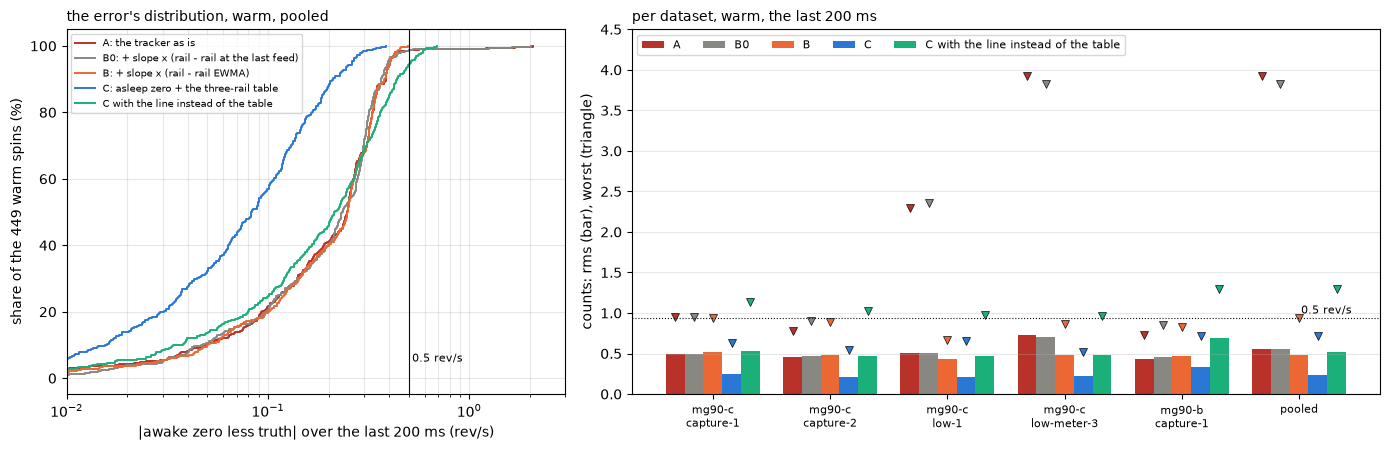

In [17]:
# the three methods: the distribution of every spin's error, and the per-dataset rms and worst
MCOL = {"A": RED, "B0": MUTED, "B": ORANGE, "C": BLUE, "Cline": GREEN}
MLAB = {"A": "A: the tracker as is", "B0": "B0: + slope x (rail - rail at the last feed)", "B": "B: + slope x (rail - rail EWMA)",
        "C": "C: asleep zero + the three-rail table", "Cline": "C with the line instead of the table"}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [2, 3]})
a = ax[0]
WM = PM[~PM["first_chain"]]
for meth in METHODS:
    e = np.sort((WM[f"{meth}_200"] * WM["rpc"]).abs().to_numpy())
    a.step(e, np.arange(1, len(e) + 1) / len(e) * 100, where="post", color=MCOL[meth], lw=1.4, label=MLAB[meth])
a.axvline(0.5, color=INK, lw=0.8); a.text(0.52, 5, "0.5 rev/s", fontsize=8)
a.set_xscale("log"); a.set_xlim(0.01, 3); a.set_xlabel("|awake zero less truth| over the last 200 ms (rev/s)"); a.set_ylabel("share of the 449 warm spins (%)")
a.set_title("the error's distribution, warm, pooled", loc="left", fontsize=10); a.grid(alpha=0.3, which="both"); a.legend(fontsize=7, loc="upper left")
a = ax[1]
sets = [f"{m}\n{n}" for m, n in SIM] + ["pooled"]
S200 = SC[SC["warm"] & (SC["when"] == "200")]
x = np.arange(len(sets))
for j, meth in enumerate(METHODS):
    r_ = [S200[(S200["method"] == meth) & (S200["name"] == n) & (S200["motor"] == m)].iloc[0] for m, n in SIM] + [S200[(S200["method"] == meth) & (S200["motor"] == "all")].iloc[0]]
    a.bar(x + (j - 2) * 0.16, [r["rms"] for r in r_], 0.16, color=MCOL[meth], label=MLAB[meth].split(":")[0])
    a.plot(x + (j - 2) * 0.16, [r["worst"] for r in r_], "v", color=MCOL[meth], mec=INK, mew=0.5, ms=6)
a.axhline(0.5 / RPC, color=INK, lw=0.8, ls=":"); a.text(5.45, 0.5 / RPC + 0.05, "0.5 rev/s", fontsize=8, ha="right")
a.set_xticks(x, sets, fontsize=8); a.set_ylabel("counts: rms (bar), worst (triangle)"); a.set_ylim(0, 4.5)
a.set_title("per dataset, warm, the last 200 ms", loc="left", fontsize=10); a.grid(alpha=0.3, axis="y"); a.legend(fontsize=8, ncol=5, loc="upper left")
plt.tight_layout(); plt.show()

Left, the share of the warm spins whose error over the last 200 ms sits under each size, one curve per method, with the 0.5 rev/s budget as the vertical line. Right, each method's rms per dataset as a bar and its worst spin as a triangle, the budget dotted. The thing to see is the blue curve, the table by the live rail with no awake tracking, reaching 100 % before the budget line on every dataset, including the four it was not read on.

Pooled over the five datasets, warm, over the last 200 ms, in counts rms and worst.

- (A) the tracker as is, 0.56 and 3.92 (0.30 and 2.08 rev/s), 7 spins past 0.5 rev/s.
- (B0) the tracker plus the slope times the rail now less the rail at the last fed tick, 0.55 and 3.82, 7 spins past.
- (B) the same with the rail learned by an EWMA, 0.48 and 0.94 (0.25 and 0.50 rev/s), none past.
- (C) the asleep zero plus the three-rail table, 0.24 and 0.72 (0.13 and 0.39 rev/s), none past, cold or warm.
- (C) with the line in place of the table, 0.52 and 1.29, 26 past.

Per dataset, warm, C reads 0.25, 0.21, 0.21, 0.22 and 0.33 counts rms on capture-1, capture-2, low-1, low-meter-3 and mg90-b, worst 0.63, 0.54, 0.65, 0.52 and 0.72, against A's 0.49, 0.46, 0.51, 0.72 and 0.43.

C wins by 2.3 times in rms and 5 times in the worst case over A, with no spin past 0.5 rev/s, on the two datasets and the motor it was not read on. High confidence in the ranking, since the rms differences are twenty times their standard errors over 449 spins and the truth's noise is common to all three. Moderate confidence in C's 0.24 as a number: it is the step's reproducibility across days and motors on this board, 0.2 to 0.3 counts, plus the asleep zero's tracking. C reads the rail the board has and needs a fresh asleep zero, which a servo that never torques off would not have.

B as worded is inert. At every torque on the 5 ms coast before the drive is an awake feed at the new rail, so the rail at the last feed is the new rail while the zero has moved under 1 % of the step. B0 only ever adds the rail's sag under load, $-0.1$ counts. B works when the rail is learned by an EWMA at the same gain on the same ticks: it takes the rail-step worst case from 3.92 to 0.94 counts and clears the 0.5 rev/s list, but its rms stays at 0.48 because the line it carries is the wrong shape, $\pm 0.5$ per rail. At 3.7 V it leaves 0.85 on low-meter-3's first spin and 1.45 at the first row of capture-1's 5 V change. B earns its extra state only where no table exists.

The best form the data support is C as the seed and A as the follower: on a rail change, the awake zero is set to the asleep zero plus the table at the rail, and the coasts, brakes and low-duty troughs then trim the last 0.3 to 0.7 counts, the trough feed's own offset included. The table is per board, since the step is the driver's quiescent current through the shunt, read from a coast at three rails at install. Two rails and a line leave half a count at the third.

## The board-side terms: what to compensate, how best

Every term stage 1 measured on this board, its size from the result files or from this notebook, what it is worth in rev/s at low speed through mg90-c's constants, and the method the data support. The ADC map's term comes from terminal-chain's residual map at the current channel's codes, read between the zero and a few low-speed readings.

In [18]:
inl = pd.read_csv(results.ROOT / "stages" / "1-board" / "terminal-chain" / "results" / f"{BOARD.key}-inl.csv")
res_at = lambda c: float(np.interp(c, inl["code"], inl["residual_counts"]))   # the ADC map's residual at a code
z0 = LEV[5.0]["asleep"]
INL = pd.DataFrame([dict(reading_ma=ma, code=z0 + ma / MA_PER_COUNT, differential_counts=res_at(z0 + ma / MA_PER_COUNT) - res_at(z0),
                         crosses_carry=int((z0 + ma / MA_PER_COUNT) // 256) != int(z0 // 256)) for ma in (30, 50, 65, 80, 150)])
RPMA = rev_s_per_ma("mg90-c")
KE_C = MOTORS["mg90-c"]["ke_mv_per_rev_s"]
tick_mv = lambda v_on: v_on / (2 * ARR) * 1e3                                 # one timer tick of window as period-average millivolts
scale_pct = (CPA / BOARD.counts_per_a - 1) * 100
lv = LEV
A_C = SC[(SC["motor"] == "all") & SC["warm"] & (SC["when"] == "200")].set_index("method")
rows = []
rows.append(dict(term="current zero, awake over asleep (the driver's quiescent current through the shunt)",
    size=f"{lv[3.7]['open_c']:.1f} / {lv[5.0]['open_c']:.1f} / {lv[7.4]['open_c']:.1f} counts = {lv[3.7]['open_c'] * MA_PER_COUNT:.1f} / {lv[5.0]['open_c'] * MA_PER_COUNT:.1f} / {lv[7.4]['open_c'] * MA_PER_COUNT:.1f} mA at 3.7 / 5 / 7.4 V, sd 0.5-0.6 per spin, concave in the rail",
    rev_s=f"{lv[3.7]['open_c'] * RPC:.1f} / {lv[5.0]['open_c'] * RPC:.1f} / {lv[7.4]['open_c'] * RPC:.1f} unlearned; a rail step {abs(STEPS['3.7 -> 5 V']) * RPC:.1f}-{abs(STEPS['5 -> 7.4 V']) * RPC:.1f} for a first spin above 20 %",
    best=f"a per-board three-rail table by the live rail seeding the awake zero (rms {A_C.loc['C', 'rms']:.2f} counts, worst {A_C.loc['C', 'worst']:.2f}, held out on four datasets), the tracker trimming (alone {A_C.loc['A', 'rms']:.2f} rms warm, {A_C.loc['A', 'worst']:.1f} on a first spin above 20 % after a rail step)"))
rows.append(dict(term="the in-drive offset's rail shape (current-scale's one constant over 3.7-8 V laps)",
    size=f"constant {DRIVE_OFF:.2f} [{CS['drive_offset_counts']['lo']:.2f}, {CS['drive_offset_counts']['hi']:.2f}] counts against {lv[3.7]['open_c']:.1f} to {lv[7.4]['open_c']:.1f}: {lv[3.7]['open_c'] - DRIVE_OFF:+.1f} / {lv[5.0]['open_c'] - DRIVE_OFF:+.1f} / {lv[7.4]['open_c'] - DRIVE_OFF:+.1f} counts at 3.7 / 5 / 7.4 V; the line {F['a']:+.2f} + {F['b']:.2f} V leaves +/-0.5 per rail",
    rev_s=f"{(lv[3.7]['open_c'] - DRIVE_OFF) * RPC:+.1f} / {(lv[5.0]['open_c'] - DRIVE_OFF) * RPC:+.1f} / {(lv[7.4]['open_c'] - DRIVE_OFF) * RPC:+.1f} with the constant; {max(abs(r) for r in F['per_level_resid'].values()) * RPC:.1f} with the line, {max(abs(r) for r in F['per_level_resid_quad'].values()) * RPC:.1f} with the table",
    best=f"the table, three points linear between, not a constant and not a line; current-scale's residual rms of {CS['residual_rms_counts']['value']:.1f} counts carries this shape"))
rows.append(dict(term="switching share: the dropout rows (e) and the dummy's trough (d) over the open bridge (b)",
    size=f"(e) - (b) = {lv[3.7]['e_minus_b']:+.2f} / {lv[5.0]['e_minus_b']:+.2f} / {lv[7.4]['e_minus_b']:+.2f} counts (n {lv[3.7]['dropout_c_n']} / {lv[5.0]['dropout_c_n']} / {lv[7.4]['dropout_c_n']} spins, sd 0.7-1.1); (d) - (b) = {lv[3.7]['d_minus_b']:+.2f} / - / {lv[7.4]['d_minus_b']:+.2f} at 3.7 / 7.4 V",
    rev_s=f"{0.6 * RPC:.2f} to {1.0 * RPC:.2f}",
    best="no term: under the 0.5 rev/s budget, and (e) at 3.7 and 5 V rests on 3-4 spins (low confidence on its size there)"))
rows.append(dict(term="window floors, terminal 93 ticks and current 64 ticks",
    size=f"terminal difference 24-41 % low at 72 ticks, +1.3 / +0.6 % at 84 (7.4 / 3.7 V), inside 0.5 % from 96; current inside 1 % from 48; v_floor_1pct {ST['v_floor_1pct_7v4']['value']:.0f} / {ST['v_floor_1pct_3v7']['value']:.0f} % duty, i_floor_1pct {ST['i_floor_1pct_7v4']['value']:.0f} / {ST['i_floor_1pct_3v7']['value']:.0f} %",
    rev_s="n/a: a gate, not a correction",
    best="keep the gates; nothing to compensate above them"))
rows.append(dict(term="edge lags per rail (the drive pulse shorter than commanded)",
    size=f"tap ON {ST['tap_on_edge_lag_3v7']['value']:.0f} [{ST['tap_on_edge_lag_3v7']['lo']:.0f}, {ST['tap_on_edge_lag_3v7']['hi']:.0f}] / {ST['tap_on_edge_lag_7v4']['value']:.0f} [{ST['tap_on_edge_lag_7v4']['lo']:.0f}, {ST['tap_on_edge_lag_7v4']['hi']:.0f}] ticks, OFF {ST['off_edge_lag_3v7']['value']:.0f} [{ST['off_edge_lag_3v7']['lo']:.0f}, {ST['off_edge_lag_3v7']['hi']:.0f}] / {ST['off_edge_lag_7v4']['value']:.0f} [{ST['off_edge_lag_7v4']['lo']:.0f}, {ST['off_edge_lag_7v4']['hi']:.0f}] at 3.7 / 7.4 V: the window 28 / 32 ticks short",
    rev_s=f"1 tick of window = {tick_mv(3.7):.2f} / {tick_mv(5.0):.2f} / {tick_mv(7.4):.2f} mV = {tick_mv(3.7) / KE_C:.2f} / {tick_mv(5.0) / KE_C:.2f} / {tick_mv(7.4) / KE_C:.2f} rev/s per tick at 3.7 / 5 / 7.4 V at any duty; the 28-32 tick shortfall itself, if scaled by the commanded width, {30 * tick_mv(5.0) / KE_C:.1f} rev/s at 5 V",
    best="a per-rail edge term on the window width in the BEMF estimate, linear in the rail between the measured rails; the 5 V reference itself is unmeasured on the dummy"))
rows.append(dict(term="window scale k (the window's V/I over the 100 % V/I, slow decay)",
    size=f"{ST['window_scale']['value']:.4f} [{ST['window_scale']['lo']:.4f}, {ST['window_scale']['hi']:.4f}] (sample-timing), {BSR['window_scale']['value']:.4f} [{BSR['window_scale']['lo']:.4f}, {BSR['window_scale']['hi']:.4f}] (bridge-states): the current 0.5-0.8 % low in a window",
    rev_s=f"{0.0063 * 50:.2f} mA at 50 mA = {0.0063 * 50 * RPMA:.2f} rev/s",
    best="no term: a third of the current scale's 2 % class; fold into the scale if a reference shunt ever grades it"))
rows.append(dict(term="ADC INL (terminal-chain's fine grid): a sawtooth per 256 codes, missing codes at each carry",
    size=f"{TC['inl_sawtooth_pp_counts']['value']:.1f} [{TC['inl_sawtooth_pp_counts']['lo']:.1f}, {TC['inl_sawtooth_pp_counts']['hi']:.1f}] counts pp; at the current channel (zero at code {z0:.0f}) between the zero and a reading: "
         + ", ".join(f"{r.reading_ma} mA {r.differential_counts:+.2f}" + (" (across the carry at 1280)" if r.crosses_carry else "") for r in INL.itertuples()),
    rev_s=f"{INL['differential_counts'].abs().max() * RPC:.2f} worst over these readings",
    best="offline only, with the chip's own map; nothing on the board"))
rows.append(dict(term="torque-off zero at a 3.3 V rail (VDD headroom lost)",
    size=f"{CS['rest_zero_3v3_counts']['value']:.1f} against {CS['rest_zero_counts']['value']:.0f} from 3.7 V up ({CS['rest_zero_3v3_counts']['value'] - CS['rest_zero_counts']['value']:+.1f} counts), VDD {CS['vdd_3v3_v']['value']:.2f} V; the reading over the line {CS['deviation_3v3_bare_pct']['value']:+.1f} % (bare) / {CS['deviation_3v3_series_pct']['value']:+.1f} % (series)",
    rev_s=f"{(CS['rest_zero_3v3_counts']['value'] - CS['rest_zero_counts']['value']) * RPC:+.1f} if a 3.7 V zero were kept; the scale 4-8 % of the reading",
    best="a 1S rail under 3.7 V stays ungraded (current-scale's rule); the asleep feed follows the zero; an offline VDD correction from vref_raw at most, one level of data"))
rows.append(dict(term="op-amp zero drift with board temperature",
    size=f"{OPA['zero_drift_counts_per_c']['value']:.3f} [{OPA['zero_drift_counts_per_c']['lo']:.3f}, {OPA['zero_drift_counts_per_c']['hi']:.3f}] counts/C, {OPA['zero_drift_counts_per_c']['value'] * 35:.1f} counts over 35 C; the per-cycle baseline wanders 1.5-3.0 counts over a dataset with slopes against the NTC of {DR['counts_per_c'].min():+.1f} to {DR['counts_per_c'].max():+.1f} counts/C, so the wander is not that tempco",
    rev_s=f"{OPA['zero_drift_counts_per_c']['value'] * 35 * RPC:.1f} over 35 C untracked; the wander {0.5 * RPC:.2f} rms",
    best="the tracker as is, the asleep zero fed at every torque off; the wander's cause open"))
rows.append(dict(term="chain gain drift with board temperature",
    size=f"{OPA['gain_drift_pct_per_c']['value']:.4f} [{OPA['gain_drift_pct_per_c']['lo']:.4f}, {OPA['gain_drift_pct_per_c']['hi']:.4f}] %/C ({OPA['gain_drift_max_pct']['value']:+.2f} % at 63 C); the amplifier alone {OPA['amp_drift_pct_per_c']['value']:.4f} %/C, the shunt about -50 ppm/C",
    rev_s=f"at 50 mA over 35 C {abs(OPA['gain_drift_pct_per_c']['value']) * 35 / 100 * 50:.3f} mA = {abs(OPA['gain_drift_pct_per_c']['value']) * 35 / 100 * 50 * RPMA:.3f} rev/s",
    best="no term, a bound; R x i carries it as 0.3 % of the copper's drop"))
rows.append(dict(term="current scale (counts per amp against the DMM)",
    size=f"{CPA:.1f} [{CS['counts_per_a']['lo']:.1f}, {CS['counts_per_a']['hi']:.1f}] counts/A, {scale_pct:+.2f} % over the nominal {BOARD.counts_per_a:.1f} from the parts (shunt {BOARD.shunt_mohm} mOhm x gain {BOARD.gain_milli / 1e3:.3f} / VDD); class {CS['counts_per_a_class_pct']['value']:.0f} % of reading; the amplifier alone {CS['amp_over_nominal_pct']['value']:+.2f} % over nominal",
    rev_s=f"at 50 mA {scale_pct / 100 * 50:.2f} mA = {scale_pct / 100 * 50 * RPMA:.2f} rev/s if R is in ohms; nothing if R is identified in the same counts",
    best="a measured scale once a reference shunt grades it below the 2 % class; until then the nominal, and R identified in counts"))
TERMS = pd.DataFrame(rows)


def to_md(df):
    cols = list(df.columns)
    out = ["| " + " | ".join(cols) + " |", "|" + "|".join("---" for _ in cols) + "|"]
    out += ["| " + " | ".join(str(v).replace("|", "/") for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(out)


display(Markdown(to_md(TERMS.rename(columns={"rev_s": "rev/s at low speed (mg90-c)", "best": "best method the data support"}))))

| term | size | rev/s at low speed (mg90-c) | best method the data support |
|---|---|---|---|
| current zero, awake over asleep (the driver's quiescent current through the shunt) | 2.5 / 5.9 / 9.4 counts = 2.2 / 5.2 / 8.3 mA at 3.7 / 5 / 7.4 V, sd 0.5-0.6 per spin, concave in the rail | 1.3 / 3.1 / 5.0 unlearned; a rail step 1.8-1.9 for a first spin above 20 % | a per-board three-rail table by the live rail seeding the awake zero (rms 0.24 counts, worst 0.72, held out on four datasets), the tracker trimming (alone 0.56 rms warm, 3.9 on a first spin above 20 % after a rail step) |
| the in-drive offset's rail shape (current-scale's one constant over 3.7-8 V laps) | constant 5.26 [4.39, 6.13] counts against 2.5 to 9.4: -2.7 / +0.6 / +4.2 counts at 3.7 / 5 / 7.4 V; the line -3.51 + 1.78 V leaves +/-0.5 per rail | -1.4 / +0.3 / +2.2 with the constant; 0.3 with the line, 0.0 with the table | the table, three points linear between, not a constant and not a line; current-scale's residual rms of 2.2 counts carries this shape |
| switching share: the dropout rows (e) and the dummy's trough (d) over the open bridge (b) | (e) - (b) = +0.67 / +0.58 / +0.63 counts (n 3 / 4 / 18 spins, sd 0.7-1.1); (d) - (b) = +0.84 / - / +0.57 at 3.7 / 7.4 V | 0.32 to 0.53 | no term: under the 0.5 rev/s budget, and (e) at 3.7 and 5 V rests on 3-4 spins (low confidence on its size there) |
| window floors, terminal 93 ticks and current 64 ticks | terminal difference 24-41 % low at 72 ticks, +1.3 / +0.6 % at 84 (7.4 / 3.7 V), inside 0.5 % from 96; current inside 1 % from 48; v_floor_1pct 8 / 7 % duty, i_floor_1pct 4 / 4 % | n/a: a gate, not a correction | keep the gates; nothing to compensate above them |
| edge lags per rail (the drive pulse shorter than commanded) | tap ON 37 [23, 51] / 42 [31, 57] ticks, OFF 13 [5, 27] / 15 [5, 29] at 3.7 / 7.4 V: the window 28 / 32 ticks short | 1 tick of window = 1.54 / 2.08 / 3.08 mV = 0.21 / 0.28 / 0.42 rev/s per tick at 3.7 / 5 / 7.4 V at any duty; the 28-32 tick shortfall itself, if scaled by the commanded width, 8.5 rev/s at 5 V | a per-rail edge term on the window width in the BEMF estimate, linear in the rail between the measured rails; the 5 V reference itself is unmeasured on the dummy |
| window scale k (the window's V/I over the 100 % V/I, slow decay) | 1.0063 [1.0046, 1.0081] (sample-timing), 1.0053 [1.0037, 1.0082] (bridge-states): the current 0.5-0.8 % low in a window | 0.32 mA at 50 mA = 0.19 rev/s | no term: a third of the current scale's 2 % class; fold into the scale if a reference shunt ever grades it |
| ADC INL (terminal-chain's fine grid): a sawtooth per 256 codes, missing codes at each carry | 2.0 [1.5, 2.5] counts pp; at the current channel (zero at code 1206) between the zero and a reading: 30 mA +0.31, 50 mA +0.10, 65 mA +0.89 (across the carry at 1280), 80 mA +1.69 (across the carry at 1280), 150 mA +0.64 (across the carry at 1280) | 0.90 worst over these readings | offline only, with the chip's own map; nothing on the board |
| torque-off zero at a 3.3 V rail (VDD headroom lost) | 1189.5 against 1206 from 3.7 V up (-16.5 counts), VDD 3.12 V; the reading over the line +8.4 % (bare) / +3.5 % (series) | -8.7 if a 3.7 V zero were kept; the scale 4-8 % of the reading | a 1S rail under 3.7 V stays ungraded (current-scale's rule); the asleep feed follows the zero; an offline VDD correction from vref_raw at most, one level of data |
| op-amp zero drift with board temperature | 0.062 [0.048, 0.077] counts/C, 2.2 counts over 35 C; the per-cycle baseline wanders 1.5-3.0 counts over a dataset with slopes against the NTC of -0.5 to +1.1 counts/C, so the wander is not that tempco | 1.2 over 35 C untracked; the wander 0.26 rms | the tracker as is, the asleep zero fed at every torque off; the wander's cause open |
| chain gain drift with board temperature | -0.0090 [-0.0107, -0.0072] %/C (-0.27 % at 63 C); the amplifier alone -0.0034 %/C, the shunt about -50 ppm/C | at 50 mA over 35 C 0.157 mA = 0.094 rev/s | no term, a bound; R x i carries it as 0.3 % of the copper's drop |
| current scale (counts per amp against the DMM) | 1135.0 [1133.8, 1136.3] counts/A, +2.40 % over the nominal 1108.5 from the parts (shunt 60 mOhm x gain 14.884 / VDD); class 2 % of reading; the amplifier alone +0.97 % over nominal | at 50 mA 1.20 mA = 0.72 rev/s if R is in ohms; nothing if R is identified in the same counts | a measured scale once a reference shunt grades it below the 2 % class; until then the nominal, and R identified in counts |

Every row's rev/s goes through mg90-c's $R$ and $K_e$, 0.53 rev/s per count. The two rows the data can grade live, the current zero and its rail shape, come out the same way: the zero is a concave function of the rail that a per-board table carries and a constant, a slope or a line does not. The rest are gates, bounds or offline corrections.

## Results

The current channel's zero on this board is two numbers and a shape. The asleep zero, with the driver disabled, sits at 1206 counts from 3.7 V up and wanders 1.5 to 3 counts over a sitting with no consistent law in temperature. The awake zero, with the driver on and no winding current, sits 2.53, 5.88 and 9.43 counts over it at 3.7, 5 and 7.4 V (2.2, 5.2 and 8.3 mA), a per-spin standard deviation of 0.5 to 0.6 counts and a standard error of 0.05, read on 396 coasts of mg90-c. mg90-b on the same board reads 6.20 and 9.49 at 5 and 7.4 V, within 0.3 counts. The coast, the dummy's slow-decay trough and the motor's dropout rows agree within a count, the two switching readings 0.6 to 0.8 counts above the coast. The step is concave in the rail: 2.6 counts/V from 3.7 to 5 V and 1.5 from 5 to 7.4 V, a line leaving $\pm 0.5$ counts per rail (0.27 rev/s) and a slope through the origin 1.1 counts rms. A quadratic with a curvature of $-0.30$ counts/V$^2$ leaves the per-spin scatter. High confidence on the levels and the concavity, moderate on the curvature.

The dynamic two-zero tracker, replayed tick-exactly over the five datasets, holds the awake zero within 0.56 counts rms (0.30 rev/s) once warm, but reads 3.9 counts (2.1 rev/s) through a first spin above 20 % after a rail step and 2.5, 5.9 and 9.4 counts (1.3, 3.1 and 5.0 rev/s) through a first drive above 20 % after boot. Of the warm spins, 7 of 449 pass 0.5 rev/s, and every one is a rail step or a boot. A rail step of 3.4 to 3.6 counts settles within 0.5 counts after 0.8 s of feed, one of 6.9 after 1.1 s. A 0.8 s coast closes 86 % of a step, a 0.3 s coast 52 %, a 20 ms brake 5 % and a 1.5 s hold at 20 % or under 97 %.

Of the three candidates, the asleep zero plus a per-board three-rail table read by the live rail wins: 0.24 counts rms, worst 0.72, no spin past 0.5 rev/s, held out on four of the five datasets and on the second motor, against 0.56 and 3.92 for the tracker as is and 0.48 and 0.94 for the tracker with a rail term through a rail EWMA. A rail term through the rail at the last feed is inert, since the 5 ms coast at every torque on is a feed at the new rail. High confidence in the ranking, moderate in the table's 0.24, which is the step's reproducibility across days and motors on this board. The form the data support is the table as the seed on a rail change and the tracker as the follower, and the firmware takes that form and these constants from this result.

The result file carries the awake step per rail in counts and mA with its standard error, the per-spin standard deviation and mg90-b's levels beside it, the asleep zero per rail, the line, the proportional slope and the quadratic with their per-rail residuals, the switching share per rail, the tracker replay's scores pooled and per dataset with the boot chain's first-row errors, the convergence times per step and the share each segment closes, the three methods' pooled scores, the recommended form with the table's three points and the tracker's constants, each motor's constants as used, and the board-side table's sizes.

In [19]:
q = results.quantity
KEY = {3.7: "3v7", 5.0: "5v0", 7.4: "7v4"}
step_counts = {KEY[lv]: q(LEV[lv]["open_c"], LEV[lv]["open_c"] - LEV[lv]["open_c_se"], LEV[lv]["open_c"] + LEV[lv]["open_c_se"], "counts") for lv in LEVELS}
step_ma = {KEY[lv]: q(LEV[lv]["open_c"] * MA_PER_COUNT, (LEV[lv]["open_c"] - LEV[lv]["open_c_se"]) * MA_PER_COUNT, (LEV[lv]["open_c"] + LEV[lv]["open_c_se"]) * MA_PER_COUNT, "mA") for lv in LEVELS}
step_sd = {KEY[lv]: q(LEV[lv]["open_c_sd"], unit="counts") for lv in LEVELS}
step_n = {KEY[lv]: q(LEV[lv]["open_c_n"], unit="coasts") for lv in LEVELS}
step_b = {KEY[lv]: q(LEV[lv]["open_b"], LEV[lv]["open_b"] - LEV[lv]["open_b_sd"] / np.sqrt(LEV[lv]["open_b_n"]), LEV[lv]["open_b"] + LEV[lv]["open_b_sd"] / np.sqrt(LEV[lv]["open_b_n"]), "counts")
          for lv in LEVELS if np.isfinite(LEV[lv]["open_b"])}
asleep = {KEY[lv]: q(LEV[lv]["asleep"], unit="counts") for lv in LEVELS}
shape = {"line_intercept_counts": q(F["a"], F["a"] - F["a_se"], F["a"] + F["a_se"], "counts"),
         "line_slope_counts_per_v": q(F["b"], F["b"] - F["b_se"], F["b"] + F["b_se"], "counts/V"),
         "line_resid_sd_counts": q(F["resid_sd"], unit="counts"),
         "line_resid_by_rail_counts": {KEY[lv]: q(r, unit="counts") for lv, r in F["per_level_resid"].items()},
         "origin_slope_counts_per_v": q(F["b_origin"], unit="counts/V"), "origin_resid_sd_counts": q(F["resid_sd_origin"], unit="counts"),
         "quadratic_counts": {"v2": q(F["quad"][0], unit="counts/V^2"), "v1": q(F["quad"][1], unit="counts/V"), "v0": q(F["quad"][2], unit="counts")},
         "quadratic_resid_sd_counts": q(F["resid_sd_quad"], unit="counts"),
         "quadratic_resid_by_rail_counts": {KEY[lv]: q(r, unit="counts") for lv, r in F["per_level_resid_quad"].items()},
         "two_point_slopes_counts_per_v": {"3v7_to_5v0": q(STEPS["3.7 -> 5 V"] / 1.3, unit="counts/V"), "5v0_to_7v4": q(STEPS["5 -> 7.4 V"] / 2.4, unit="counts/V")},
         "mg90b_slope_5v0_to_7v4_counts_per_v": q(FITS["open mg90-b"]["b"], FITS["open mg90-b"]["b"] - FITS["open mg90-b"]["b_se"], FITS["open mg90-b"]["b"] + FITS["open mg90-b"]["b_se"], "counts/V"),
         "n_spins": q(F["n"], unit="coasts")}
share = {"dropout_minus_coast_counts": {KEY[lv]: q(LEV[lv]["e_minus_b"], unit="counts") for lv in LEVELS},
         "dropout_spins": {KEY[lv]: q(LEV[lv]["dropout_c_n"], unit="spins") for lv in LEVELS},
         "dummy_trough_minus_coast_counts": {KEY[lv]: q(LEV[lv]["d_minus_b"], unit="counts") for lv in LEVELS if not LEV[lv]["trough_above_feed_limit"]},
         "dummy_trough_5v0_above_feed_limit_minus_coast_counts": q(LEV[5.0]["d_minus_b"], unit="counts")}


def replay_q(r):
    return {"rms_200_counts": q(r["rms_200"], unit="counts"), "worst_200_counts": q(r["worst_200"], unit="counts"),
            "rms_200_rev_s": q(r["rms_200_rev_s"], unit="rev/s"), "worst_200_rev_s": q(r["worst_200_rev_s"], unit="rev/s"),
            "rms_start_counts": q(r["rms_start"], unit="counts"), "worst_start_counts": q(r["worst_start"], unit="counts"),
            "spins_over_half_rev_s_200": q(r["over_half_200"], unit="spins"), "spins_over_half_rev_s_start": q(r["over_half_start"], unit="spins"),
            "spins": q(r["spins"], unit="spins")}


replay = {"warm_pooled": replay_q(SUMW.iloc[-1]), "all_pooled": replay_q(SUMALL),
          "warm_by_dataset": {f"{r['motor']} {r['name']}": replay_q(r) for _, r in SUMW.iloc[:-1].iterrows()},
          "variants_warm_pooled_rms_200_counts": {f"{r['mode']} brake {r['brake_s']:g} s": q(r["rms_200"], unit="counts") for _, r in SENS.iterrows()},
          "boot_first_row_counts": {f"{r['motor']} {r['name']}": q(r["err_start"], unit="counts") for _, r in FC.groupby(["motor", "name"], sort=False).first().reset_index().iterrows()},
          "feeding_rung_end_offset_counts": q(fe["err_end"].mean(), fe["err_end"].mean() - fe["err_end"].std(ddof=1), fe["err_end"].mean() + fe["err_end"].std(ddof=1), "counts"),
          "non_feeding_rung_sd_counts": q(nf["err_200"].std(ddof=1), unit="counts")}
conv = {"settle_within_half_count_s": {k.replace(" -> ", "_to_").replace(" ", "_").replace(".", "v"): q(r["settle_s_exact"], unit="s") for k, r in SETTLE.set_index("step").iterrows()},
        "step_counts": {k.replace(" -> ", "_to_").replace(" ", "_").replace(".", "v"): q(s, unit="counts") for k, s in STEPS.items()},
        "fraction_closed": {k: q(r["fraction_closed"], unit="ratio") for k, r in FRAC_CLOSED.set_index("segment").iterrows()},
        "sag_8v4_to_7v0_move_counts": {r["shape"].replace(" ", "_"): q(r["move_counts"], unit="counts") for _, r in SAG.iterrows()},
        "tau_s": q(TAU_S, unit="s")}
meth = {m: {"rms_200_counts": q(A_C.loc[m, "rms"], unit="counts"), "worst_200_counts": q(A_C.loc[m, "worst"], unit="counts"),
            "rms_200_rev_s": q(A_C.loc[m, "rms_rev_s"], unit="rev/s"), "worst_200_rev_s": q(A_C.loc[m, "worst_rev_s"], unit="rev/s"),
            "spins_over_half_rev_s": q(A_C.loc[m, "over_half"], unit="spins"),
            "rms_by_dataset_counts": {f"{mo} {n}": q(S200[(S200["method"] == m) & (S200["motor"] == mo) & (S200["name"] == n)].iloc[0]["rms"], unit="counts") for mo, n in SIM}}
        for m in METHODS}
form = {"form": "on a rail change the awake zero := the asleep zero + table(rail); the coasts, brakes and low-duty troughs then trim",
        "table_counts": {KEY[v]: q(z, unit="counts") for v, z in zip(CAL_V, CAL_Z)},
        "table_source": "mg90-c capture-1, the open bridge 1-20 ms after the coast cut, per rail",
        "ewma_alpha_shift": q(ALPHA_SHIFT, unit="bits"), "state_frac_bits": q(FRAC, unit="bits"), "stale_ticks": q(STALE_TICKS, unit="ticks"),
        "settle_ticks": q(ZERO_SETTLE_TICKS, unit="ticks"), "trough_feed_max_ticks": q(TROUGH_FEED_MAX_TICKS, unit="ticks"),
        "brake_min_ticks": q(BIAS_BRAKE_MIN_TICKS, unit="ticks")}
terms = {"current_zero_unlearned_rev_s": {KEY[lv]: q(LEV[lv]["open_c"] * RPC, unit="rev/s") for lv in LEVELS},
         "rail_step_first_spin_rev_s": {"3v7_to_5v0": q(abs(STEPS["3.7 -> 5 V"]) * RPC, unit="rev/s"), "5v0_to_7v4": q(abs(STEPS["5 -> 7.4 V"]) * RPC, unit="rev/s")},
         "drive_offset_constant_error_counts": {KEY[lv]: q(LEV[lv]["open_c"] - DRIVE_OFF, unit="counts") for lv in LEVELS},
         "switching_share_rev_s": q(0.6 * RPC, 0.6 * RPC, 1.0 * RPC, "rev/s"),
         "tick_of_window_rev_s": {KEY[lv]: q(tick_mv(lv) / KE_C, unit="rev/s") for lv in LEVELS},
         "window_scale_at_50ma_rev_s": q(0.0063 * 50 * RPMA, unit="rev/s"),
         "inl_differential_worst_counts": q(INL["differential_counts"].abs().max(), unit="counts"),
         "zero_3v3_if_3v7_kept_rev_s": q((CS["rest_zero_3v3_counts"]["value"] - CS["rest_zero_counts"]["value"]) * RPC, unit="rev/s"),
         "zero_tempco_over_35c_rev_s": q(OPA["zero_drift_counts_per_c"]["value"] * 35 * RPC, unit="rev/s"),
         "baseline_wander_range_counts": q(DR["zero_range"].mean(), DR["zero_range"].min(), DR["zero_range"].max(), "counts"),
         "baseline_vs_ntc_counts_per_c": {f"{r['motor']} {r['name']}": q(r["counts_per_c"], r["counts_per_c"] - r["counts_per_c_se"], r["counts_per_c"] + r["counts_per_c_se"], "counts/C") for _, r in DR.iterrows()},
         "gain_drift_at_50ma_35c_rev_s": q(abs(OPA["gain_drift_pct_per_c"]["value"]) * 35 / 100 * 50 * RPMA, unit="rev/s"),
         "scale_at_50ma_rev_s": q(scale_pct / 100 * 50 * RPMA, unit="rev/s"), "scale_over_nominal_pct": q(scale_pct, unit="%")}
mot = {"mg90-c": {"ke_mv_per_rev_s": q(MOTORS["mg90-c"]["ke_mv_per_rev_s"], unit="mV per rev/s"), "ke_coasts": q(MOTORS["mg90-c"]["ke_n"], unit="coasts"),
                  "r_ohm": q(MOTORS["mg90-c"]["r_ohm"], MOTORS["mg90-c"]["r_lo"], MOTORS["mg90-c"]["r_hi"], "ohm"), "rev_s_per_count": q(rev_s_per_count("mg90-c"), unit="rev/s")},
       "mg90-b": {"ke_mv_per_rev_s": q(MOTORS["mg90-b"]["ke_mv_per_rev_s"], unit="mV per rev/s"),
                  "r_ohm": q(MOTORS["mg90-b"]["r_ohm"], MOTORS["mg90-b"]["r_lo"], MOTORS["mg90-b"]["r_hi"], "ohm"), "rev_s_per_count": q(rev_s_per_count("mg90-b"), unit="rev/s")}}
NOTES = ("compensation grades the board's terms for a low-speed current reading and the dynamic two-zero tracker against the stage 1 captures and the "
         "stage 2 bemf-coast datasets of mg90-c (capture-1, capture-2, low-1, low-meter-3) and mg90-b (capture-1). awake_step_*: the open bridge 1-20 ms "
         "after each coast cut over the cycle's torque-off baseline mean, per rail, mg90-c, the bounds one standard error over the coasts; "
         "awake_step_mg90b_counts the same on mg90-b. asleep_zero_counts: the baseline mean per rail. step_shape: the fits of the step against "
         "the coast's rail per spin. switching_share: the dropout rows and the dummy's slow-decay trough over the open bridge. tracker_replay: the "
         "tick-exact port through each dataset's timeline, the error of the awake zero against the dataset's own per-rail open bridge; warm = the "
         "dataset's first chain left out; the primary replay feeds the dummy's trough level with a 20 ms brake, the variants the dropout level (e), "
         "the open bridge (b) and a 1 s brake. convergence: the exact port under continuous dithered feed. methods_pooled: A the tracker, B0 the "
         "tracker + slope x (rail - rail at the last feed), B with a rail EWMA, C the asleep zero + mg90-c capture-1's three-rail table by the live "
         "rail, Cline the same with the line; warm, the last 200 ms. recommended_form: C as the seed on a rail change, the tracker trimming. "
         "board_terms: each term in rev/s at low speed through mg90-c's own R and Ke. motor_constants: mg90-c's from its own stall pass and coasts, "
         "mg90-b's from its stage 2 results.")
out = results.write(
    "1-board", "compensation", folder_of("mg90-c", "capture-1"), pair=BOARD.key, notes=NOTES,
    awake_step_counts=step_counts, awake_step_ma=step_ma, awake_step_spin_sd_counts=step_sd, awake_step_coasts=step_n, awake_step_mg90b_counts=step_b,
    asleep_zero_counts=asleep, step_shape=shape, switching_share=share, tracker_replay=replay, convergence=conv, methods_pooled=meth,
    recommended_form=form, board_terms=terms, motor_constants=mot,
    rev_s_per_count_mg90c=q(RPC, unit="rev/s"), ma_per_count=q(MA_PER_COUNT, unit="mA"))
print(out)

stages/1-board/compensation/results/dev-v006-2A-D.json


## Limitations

- The motor's trough under a low-duty drive was never streamed, since the stage 2 sweeps carry the R/L field set. (d) is the dummy's, at the feeding widths only at 3.7 and 7.4 V and interpolated at 5 V through (d) minus (b). The replay's settled offset on feeding rungs, $+0.4$ to $+0.75$ counts, is that model and not a measurement.
- The capture tool's brake lasted 20 ms or 1 s on the pot-less rig, unrecorded. Both run, the primary is 20 ms.
- The rests are synthesized at the baseline level with white noise, so the asleep zero's wander within a rest is not modeled, and mg90-b's segment times are synthesized from capture-1's median gap, which pools the 5 ms gap after a baseline with the gap between chains.
- Each dataset is seeded at its own first baseline, the boot case. The real sittings chained datasets, so the first chain's errors are reported apart as the boot case and left out of the warm summaries.
- The method measures against the previous tick's command, one tick of offset, ignored here.
- The truth is the dataset's own per-rail mean. Against each spin's own coast zero every rms rises by about 0.3 counts.
- One board. The step is a board property, and the sister board's rest zero differs by 150 counts, so its step is its own to measure.
- No stage 2 dataset reaches 3.3 V and none goes above 7.4 V, so the 3.3 V zero rests on stage 1's rests alone and the 2S sag question on an extrapolation.

## Open questions

- The baseline's wander, 1.5 to 3 counts over a dataset with slopes against the NTC from $+1.1$ to $-0.5$ counts/C between datasets. If it is the amplifier's input pair or the pull-ups warming with the board's own heat, a torque-off stream with the NTC through a heated plateau reads it against temperature alone, as opamp-temperature did at 0.062 counts/C. If it is the rail or the reference, it follows `vref_raw` and `vbus_raw` in the same stream. If it is the join or the leads, it stays on a rest with the motor unplugged.
- The 5 V trough on the motor. A sweep at 15 and 20 % that carries the trough sample in the row, on the motor, reads (d) directly where the replay models it, and says whether the dummy's one count between wirings is in the load or in the board.
- The step beyond 7.4 V. A coast ladder at 7.4, 7.8 and 8.2 V on the same motor separates the line from the quadratic where a 2S pack sits, and sizes the sag term, 0.4 to 1.3 rev/s here.
- The frame's two shunt samples at rest, the crest 0.07 to 0.50 counts under the trough between the bridge-states sweeps. A rest stream with both samples in the row, at the three rails, says whether a trough-fed zero under a crest reading carries a systematic.
- Whether the table holds on a board after a different session's install. The same three-rail coast on the sister board, and again on this one weeks apart, bounds the per-board table's drift against the 0.3 counts it reproduces to here.

## Conclusion

The board's largest term at low current is the current zero's step between the bridge asleep and awake, 2.5 to 9.4 counts from 3.7 to 7.4 V, 1.3 to 5.0 rev/s if unlearned, concave in the rail. Three points carry it, and a constant, a slope through zero or a line through two rails does not. The dynamic two-zero tracker follows the zero to 0.56 counts rms once warm, inside the 0.5 rev/s budget, and loses it for a whole spin above 20 % after a rail step or a boot, 1.8 to 5 rev/s. A per-board table of the step at three rails, read by the live rail and added to the asleep zero, holds every spin inside the budget on captures and a motor it was not read on, 0.24 counts rms. The form the data support is that table seeding the awake zero on a rail change and the tracker trimming the rest, and the firmware takes its zero method, the table's three points and the tracker's constants from here.

The rest of the board's terms are small or belong elsewhere. The switching share is 0.6 mA, under the budget. The window floors are gates. The edge lags are a voltage-side term for the BEMF estimate, 0.2 to 0.4 rev/s per tick of window, measured at two rails. The window scale, the gain drift and the current scale are bounds of a percent or less that cancel where $R$ is identified in the same counts. The ADC's map is corrected offline or not at all. Nothing under a 3.7 V rail is graded.

Later stages should take three things from here. A current reading's zero at low speed is the awake zero at the live rail, and a stage that reads a current at a rail it did not rest at needs the table. The baseline wanders a count or two over a sitting for reasons not yet measured, so a zero is read in the same cycle as the reading it serves. And the trough the method feeds on was never streamed on a motor, so the next capture on a motor at 20 % or under carries the trough sample in its row.